# NGC 628: global source-integral implementation and validation

**Stage:** numerical implementation and real-data reference calculation,
**not a completed new seven-parameter posterior**. Old fits are retained.
All new products go to `outputs/implications/NGC628_source_integral_refit/`.

This notebook implements the next correction after the raw-window projection
refit. The actual source field is transported before annular projection, the
same-event integral retains source smoothing instead of a midpoint replacement,
and the full elliptical face-on beam covariance is added to each endpoint
kernel. The distinct-event term remains one $C_{\rm NP}$ with axisymmetric
source weights only; its nonlocal radial response is a numerical extension of
the locally uniform leading term, **not** a new arm-coupled term.

The observed abundance construction is held fixed as a control. Metallicity
holes stay NaN and every valid pixel pair is used. Source preparation separates
geometric coverage, detected star-forming cells, low-EW cells assumed quiet in
the chosen tracer, and unclassified covered cells. Unknown cells are not
asserted to have zero source rate. Fixed H-alpha completion and radial
extrapolation are documented assumptions, not recovered observations.

The final real-data calculation fixes the same seven coordinates at one actual
joint draw from the previous posterior. Its curve is explicitly a **reference
point**, not a posterior median or a maximum-likelihood fit. No new posterior
16–84% interval is fabricated. Main scientific fit comparisons must continue
to use posterior medians once all corrections are validated and resampled.

Before a new MCMC: validate precision across the physical prior, construct and
test a fast response emulator, run native multi-line injection/recovery, obtain
independently restarted ensembles and target-statistic ESS, and rerun the same
algorithm for the four galaxies and three geometry controls. Current manuscript
figures/tables are not replaced by this NGC628-only diagnostic.


In [1]:
from __future__ import annotations

import hashlib
from io import BytesIO
import json
import shutil
import sys
import tarfile
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from IPython.display import Image, Markdown, display
from scipy.integrate import simpson
from scipy.ndimage import gaussian_filter, map_coordinates
from scipy.signal import fftconvolve
from scipy.spatial import cKDTree
from scipy.special import exp1
from scipy.stats import chi2, linregress

ROOT = Path.cwd()
GALAXY_NAME = "NGC628"
DATA_ROOT = ROOT / "data" / "phangs"
OUTPUT_ROOT = ROOT / "outputs" / "implications"
DATA_DIR = DATA_ROOT
OUTPUT_DIR = OUTPUT_ROOT / "NGC628_source_integral_refit"
CATALOG_PATH = DATA_DIR / "NGC0628_catalog.fits"
NEBULA_MASK_PATH = DATA_DIR / "NGC0628_nebulae_mask.fits"
MUSE_MAPS_PATH = DATA_DIR / "NGC0628_MAPS_copt_0.92asec.fits"
R_BAND_PATH = DATA_DIR / "NGC0628_PHANGS_IMAGE_SDSS_r_copt_0.92asec.fits"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "font.size": 10,
    "axes.grid": False,
})


def display_figure(figure):
    """Render without calling show() on a non-interactive Agg canvas."""
    buffer = BytesIO()
    figure.savefig(buffer, format="png", dpi=plt.rcParams["figure.dpi"],
                   bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(figure)


# NGC 628 geometry used by the PHANGS catalogue.
DISTANCE_MPC = 9.8
R25_ARCMIN = 4.9
INCLINATION_DEG = 8.9
POSITION_ANGLE_DEG = 20.7
R25_KPC = DISTANCE_MPC * 1.0e3 * np.tan(np.deg2rad(R25_ARCMIN / 60.0))

# Spatial and quality choices for the direct MUSE map.
COPT_PSF_FWHM_ARCSEC = 0.92
TARGET_FWHM_KPC = 0.120
PIXEL_SIZE_KPC = 0.060
ANNULUS_WIDTH_KPC = 0.20
LINE_SN_MIN = 2.0
LINE_COVERAGE_MIN = 0.80
HALPHA_EW_MIN_ANGSTROM = 6.0
METALLICITY_ERROR_MAX_DEX = None
MUSE_ERROR_INFLATION = 1.12
N_FLUX_MC = 200
MIN_PIXELS_PER_ANNULUS = 20
R_MIN_R25 = 0.10
R_MAX_R25 = 0.40
R_MIN_KPC = R_MIN_R25 * R25_KPC
R_MAX_KPC = R_MAX_R25 * R25_KPC

print(f"R25 = {R25_KPC:.3f} kpc; analysis annulus = "
      f"[{R_MIN_KPC:.3f}, {R_MAX_KPC:.3f}] kpc")
print(f"Target PSF/pixel = {TARGET_FWHM_KPC:.3f}/{PIXEL_SIZE_KPC:.3f} kpc")


R25 = 13.968 kpc; analysis annulus = [1.397, 5.587] kpc
Target PSF/pixel = 0.120/0.060 kpc


## 1. Download the PHANGS--MUSE line maps, continuum image, and masks

The primary abundance input is the official 0.92 arcsec `copt` MAPS file, not
a reconstructed metallicity field.  The matched synthetic SDSS-$r$ image has
flux-density units and supplies the local continuum proxy for the H-alpha
equivalent-width cut.  The nebular catalogue and mask calibrate that proxy and
determine the disc-coordinate transformation; they do not select abundance pixels.
The MAPS and SDSS-$r$ downloads are approximately 814 MiB and 17 MiB.

Set `FORCE_DOWNLOAD=True` only when the archived products should be refreshed.


In [2]:
CATALOG_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2025-05-14T09:12:30.213"
)
NEBULA_MASK_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2025-05-14T09:12:30.214"
)
MUSE_MAPS_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2021-07-16T10:20:56.338"
)
R_BAND_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2021-07-16T10:20:56.336"
)
MUSE_MAPS_PRODUCT_ID = "ADP.2021-07-16T10:20:56.338"
R_BAND_PRODUCT_ID = "ADP.2021-07-16T10:20:56.336"


def download_product(url: str, path: Path, force: bool = False) -> Path:
    """Download one public product atomically."""
    if path.exists() and not force:
        return path
    temporary = path.with_suffix(path.suffix + ".part")
    with urlopen(url, timeout=300) as response:
        with temporary.open("wb") as stream:
            shutil.copyfileobj(response, stream)
    temporary.replace(path)
    return path


def sha256_file(path: Path, chunk_size: int = 8 * 1024**2) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        while chunk := stream.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()


FORCE_DOWNLOAD = False
for product_url, product_path in (
    (CATALOG_URL, CATALOG_PATH),
    (NEBULA_MASK_URL, NEBULA_MASK_PATH),
    (MUSE_MAPS_URL, MUSE_MAPS_PATH),
    (R_BAND_URL, R_BAND_PATH),
):
    download_product(product_url, product_path, force=FORCE_DOWNLOAD)

catalog_hash = sha256_file(CATALOG_PATH)
nebula_mask_hash = sha256_file(NEBULA_MASK_PATH)
muse_maps_hash = sha256_file(MUSE_MAPS_PATH)
r_band_hash = sha256_file(R_BAND_PATH)
for product_name, product_path, product_hash in (
    ("PHANGS nebular catalogue", CATALOG_PATH, catalog_hash),
    ("PHANGS nebular mask", NEBULA_MASK_PATH, nebula_mask_hash),
    ("PHANGS--MUSE copt MAPS", MUSE_MAPS_PATH, muse_maps_hash),
    ("PHANGS--MUSE copt SDSS-r continuum", R_BAND_PATH, r_band_hash),
):
    print(f"{product_name}: {product_path}")
    print(f"Size: {product_path.stat().st_size / 1024**2:.2f} MiB")
    print(f"SHA256: {product_hash}")


# Querejeta et al. (2021) PHANGS pixel-level environment masks.
PHANGS_ENVIRONMENT_MASK_BUNDLE_URL = (
    "https://www.canfar.net/storage/vault/file/AstroDataCitationDOI/"
    "CISTI.CANFAR/21.0024/data/PHANGS_env_masks.bundle.tar.gz"
)
ENVIRONMENT_ARCHIVE_DIR = DATA_ROOT / "environment_masks"
ENVIRONMENT_ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)
ENVIRONMENT_BUNDLE_PATH = (
    ENVIRONMENT_ARCHIVE_DIR / "PHANGS_env_masks.bundle.tar.gz"
)
mask_galaxy_name = "NGC0628" if GALAXY_NAME == "NGC628" else GALAXY_NAME
mask_member = (
    "PHANGS_env_masks/env_masks_simple/"
    f"{mask_galaxy_name}_env_mask_simple.fits"
)
ENVIRONMENT_MASK_PATH = ENVIRONMENT_ARCHIVE_DIR / mask_member
if not ENVIRONMENT_MASK_PATH.exists() or FORCE_DOWNLOAD:
    # the bundle is fetched only when the extracted mask is missing (offline re-runs)
    download_product(
        PHANGS_ENVIRONMENT_MASK_BUNDLE_URL, ENVIRONMENT_BUNDLE_PATH,
        force=FORCE_DOWNLOAD,
    )
    with tarfile.open(ENVIRONMENT_BUNDLE_PATH, "r:gz") as archive:
        archive.extract(mask_member, path=ENVIRONMENT_ARCHIVE_DIR, filter="data")
environment_mask_hash = sha256_file(ENVIRONMENT_MASK_PATH)
print(f"PHANGS environment mask: {ENVIRONMENT_MASK_PATH}")
print(f"SHA256: {environment_mask_hash}")


PHANGS nebular catalogue: /Users/meow/Latex/KT+SpiralArms/data/phangs/NGC0628_catalog.fits
Size: 1.68 MiB
SHA256: 858a9b959102514841a80b9870e267de1e7887ee836a7524d3fb081a8f155144
PHANGS nebular mask: /Users/meow/Latex/KT+SpiralArms/data/phangs/NGC0628_nebulae_mask.fits
Size: 7.68 MiB
SHA256: 49cecc076970bb2bcc764386c65822355769e11be4a0fb2c18841827484baace
PHANGS--MUSE copt MAPS: /Users/meow/Latex/KT+SpiralArms/data/phangs/NGC0628_MAPS_copt_0.92asec.fits
Size: 814.47 MiB
SHA256: 682eeab82385db3a0fc64757db43c13d449f0c3847e25e34b8779d963227bae5
PHANGS--MUSE copt SDSS-r continuum: /Users/meow/Latex/KT+SpiralArms/data/phangs/NGC0628_PHANGS_IMAGE_SDSS_r_copt_0.92asec.fits
Size: 17.32 MiB
SHA256: de8b764413168c1a3f10a54c652a259d3252cbd3125fcc49dcda1bdfa5f1bff4
PHANGS environment mask: /Users/meow/Latex/KT+SpiralArms/data/phangs/environment_masks/PHANGS_env_masks/env_masks_simple/NGC0628_env_mask_simple.fits
SHA256: 2c7c41b56612c3bc80de4e6b0a3da37db7fabc08f737b36a41c7cca902251860


## 2. Retain the catalogue-calibrated face-on coordinate transform

The catalogue sets the external spatial transform and reference radius only. No metallicity residual is used to fit the source geometry. The revised padded source is constructed in section 4.


In [3]:
catalog = Table.read(CATALOG_PATH)


def numeric_column(name: str) -> np.ndarray:
    return np.asarray(np.ma.asarray(catalog[name]).filled(np.nan), dtype=float)


catalog_r_r25 = numeric_column("DEPROJ_R_R25")
catalog_r_kpc = catalog_r_r25 * R25_KPC
catalog_phi = numeric_column("DEPROJ_PHI")
catalog_target_xy = np.column_stack((
    catalog_r_kpc * np.cos(catalog_phi),
    catalog_r_kpc * np.sin(catalog_phi),
))
catalog_ra = numeric_column("RAJ2000")
catalog_dec = numeric_column("DECJ2000")
sky_reference_ra = float(np.nanmedian(catalog_ra))
sky_reference_dec = float(np.nanmedian(catalog_dec))


def sky_design_matrix(ra_deg: np.ndarray, dec_deg: np.ndarray) -> np.ndarray:
    """Return local east, north [kpc] and an affine intercept column."""
    ra_deg = np.asarray(ra_deg, dtype=float)
    dec_deg = np.asarray(dec_deg, dtype=float)
    angular_to_kpc = np.pi / 180.0 * DISTANCE_MPC * 1.0e3
    east = ((ra_deg - sky_reference_ra)
            * np.cos(np.deg2rad(sky_reference_dec)) * angular_to_kpc)
    north = (dec_deg - sky_reference_dec) * angular_to_kpc
    return np.column_stack((east, north, np.ones_like(east)))


catalog_sky_design = sky_design_matrix(catalog_ra, catalog_dec)
transform_inlier = (
    np.all(np.isfinite(catalog_sky_design), axis=1)
    & np.all(np.isfinite(catalog_target_xy), axis=1)
)
for _ in range(6):
    face_on_affine = np.linalg.lstsq(
        catalog_sky_design[transform_inlier],
        catalog_target_xy[transform_inlier], rcond=None,
    )[0]
    transform_residual = np.hypot(*(
        catalog_sky_design @ face_on_affine - catalog_target_xy
    ).T)
    median_residual = np.median(transform_residual[transform_inlier])
    residual_mad = np.median(np.abs(
        transform_residual[transform_inlier] - median_residual
    ))
    clipping_radius = max(0.10, median_residual + 10.0 * 1.4826 * residual_mad)
    transform_inlier = np.isfinite(transform_residual) & (
        transform_residual < clipping_radius
    )


def project_sky_to_face_on(
    ra_deg: np.ndarray, dec_deg: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    xy = sky_design_matrix(ra_deg, dec_deg) @ face_on_affine
    return xy[:, 0], xy[:, 1]


def project_face_on_to_sky(
    x_kpc: np.ndarray, y_kpc: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    xy = np.column_stack((np.ravel(x_kpc), np.ravel(y_kpc)))
    east_north = (xy - face_on_affine[2]) @ np.linalg.inv(face_on_affine[:2])
    angular_to_kpc = np.pi / 180.0 * DISTANCE_MPC * 1.0e3
    ra = (sky_reference_ra + east_north[:, 0]
          / (angular_to_kpc * np.cos(np.deg2rad(sky_reference_dec))))
    dec = sky_reference_dec + east_north[:, 1] / angular_to_kpc
    return ra, dec


face_on_x_all, face_on_y_all = project_sky_to_face_on(catalog_ra, catalog_dec)
face_on_r_kpc_all = np.hypot(face_on_x_all, face_on_y_all)
face_on_phi_all = np.mod(np.arctan2(face_on_y_all, face_on_x_all), 2.0 * np.pi)
r_r25_all = catalog_r_r25

catalog_hii_quality = (
    (numeric_column("FLAG_EDGE") == 0)
    & (numeric_column("FLAG_STAR") == 0)
    & (numeric_column("BPT_NII") == 0)
    & np.isfinite(numeric_column("HA6562_LUM_CORR"))
    & (numeric_column("HA6562_LUM_CORR") > 0)
)
source_mask = (
    catalog_hii_quality
    & (r_r25_all >= R_MIN_R25)
    & (r_r25_all <= R_MAX_R25)
)
source_r_kpc_catalog = face_on_r_kpc_all[source_mask]
source_phi_catalog = face_on_phi_all[source_mask]
source_environment_catalog = numeric_column("ENVIRONMENT")[source_mask].astype(int)
source_halpha_catalog = numeric_column("HA6562_LUM_CORR")[source_mask]
source_catalog_weights = source_halpha_catalog / np.sum(source_halpha_catalog)
r_ref_kpc = float(np.exp(np.sum(
    source_catalog_weights * np.log(source_r_kpc_catalog)
)))
hii_region_ids = numeric_column("REGION_ID")[catalog_hii_quality].astype(int)

environment_labels, environment_counts = np.unique(
    source_environment_catalog, return_counts=True
)
display(Table({
    "environment_label": environment_labels,
    "qualified_HII_regions": environment_counts,
}))


environment_label,qualified_HII_regions
int64,int64
6,1292
7,767


## 3. Construct the Li21-style spaxel metallicity fluctuation map

All available line fluxes and the SDSS-$r$ continuum-density image are first
brought to a common 120 pc Gaussian PSF and then sampled on a 60 pc face-on
grid.  Ratios and abundances are calculated only after this linear processing.
Internal attenuation is inferred from the Balmer decrement using an O'Donnell
$R_V=3.1$ curve.  The Pilyugin & Grebel (2016) $S$ calibration uses $R_3$,
$N_2$, and $S_2$; its upper/lower branch is selected independently in every
cell.

Following Li21, pixels are retained when every line needed by the diagnostic
has $S/N\geq2$, the [N II] BPT ratios lie below the Kewley boundary, and
$\mathrm{EW}({\rm H}\alpha)>6$ Angstrom.  The public MAPS product does not
contain a continuum extension, so the matched synthetic SDSS-$r$ flux density
is used for the continuum.  Its H-alpha/continuum ratio is calibrated against
the catalogue's fitted region-integrated H-alpha equivalent widths; the
calibration scatter is reported below.  The nebular segmentation never enters
the abundance-pixel mask.  Missing cells are `NaN`, never physical zeros.


In [4]:
LINE_EXTENSIONS = {
    "hb": "HB4861",
    "oiii": "OIII5006",
    "ha": "HA6562",
    "nii": "NII6583",
    "sii6716": "SII6716",
    "sii6730": "SII6730",
}
LINE_WAVELENGTH_ANGSTROM = {
    "hb": 4861.35,
    "oiii": 5006.84,
    "ha": 6562.79,
    "nii": 6583.45,
    "sii6716": 6716.44,
    "sii6730": 6730.82,
}


def odonnell_k(wavelength_angstrom: float, rv: float = 3.1) -> float:
    """O'Donnell (1994) optical A(lambda)/E(B-V)."""
    x = 1.0 / (wavelength_angstrom * 1.0e-4)
    y = x - 1.82
    a = (1.0 + 0.104*y - 0.609*y**2 + 0.701*y**3 + 1.137*y**4
         - 1.718*y**5 - 0.827*y**6 + 1.647*y**7 - 0.505*y**8)
    b = (1.952*y + 2.908*y**2 - 3.989*y**3 - 7.985*y**4
         + 11.102*y**5 + 5.491*y**6 - 10.805*y**7 + 3.347*y**8)
    return float(rv * a + b)


extinction_k = {
    name: odonnell_k(wavelength)
    for name, wavelength in LINE_WAVELENGTH_ANGSTROM.items()
}

grid_half_pixels = int(np.ceil(R_MAX_KPC / PIXEL_SIZE_KPC))
pixel_centres = np.arange(-grid_half_pixels, grid_half_pixels + 1) * PIXEL_SIZE_KPC
pixel_X, pixel_Y = np.meshgrid(pixel_centres, pixel_centres)
pixel_R = np.hypot(pixel_X, pixel_Y)
pixel_PHI = np.mod(np.arctan2(pixel_Y, pixel_X), 2.0 * np.pi)
target_ra, target_dec = project_face_on_to_sky(pixel_X, pixel_Y)


def gaussian_kernel_square_sum(sigma_pixel: float, truncate: float = 4.0) -> float:
    if sigma_pixel <= 0:
        return 1.0
    radius = int(truncate * sigma_pixel + 0.5)
    coordinate = np.arange(-radius, radius + 1, dtype=float)
    kernel_1d = np.exp(-0.5 * (coordinate / sigma_pixel)**2)
    kernel_1d /= np.sum(kernel_1d)
    return float(np.sum(kernel_1d**2)**2)


def smooth_and_sample_line(
    flux_native: np.ndarray, error_native: np.ndarray,
    sample_coordinates: np.ndarray, sigma_pixel: float,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """PSF-match surface-brightness and sample it on the face-on grid."""
    good = np.isfinite(flux_native) & np.isfinite(error_native) & (error_native > 0)
    flux_zero = np.where(good, flux_native, 0.0).astype(np.float32)
    variance_zero = np.where(good, error_native**2, 0.0).astype(np.float32)
    if sigma_pixel > 0:
        weight = gaussian_filter(good.astype(np.float32), sigma_pixel,
                                 mode="constant", cval=0.0, truncate=4.0)
        numerator = gaussian_filter(flux_zero, sigma_pixel, mode="constant",
                                    cval=0.0, truncate=4.0)
        # For independent native-pixel errors, convolution by K propagates
        # variance with K^2.  K^2 is a narrower Gaussian times sum(K^2).
        variance_numerator = gaussian_filter(
            variance_zero, sigma_pixel / np.sqrt(2.0), mode="constant",
            cval=0.0, truncate=4.0,
        ) * gaussian_kernel_square_sum(sigma_pixel)
        smoothed_flux = np.divide(
            numerator, weight, out=np.full_like(numerator, np.nan),
            where=weight > 0,
        )
        smoothed_error = np.divide(
            np.sqrt(np.clip(variance_numerator, 0.0, None)), weight,
            out=np.full_like(numerator, np.nan), where=weight > 0,
        )
    else:
        weight = good.astype(np.float32)
        smoothed_flux = np.where(good, flux_native, np.nan)
        smoothed_error = np.where(good, error_native, np.nan)

    sampled_flux = map_coordinates(
        smoothed_flux, sample_coordinates, order=1, mode="constant", cval=np.nan,
    ).reshape(pixel_X.shape)
    sampled_error = map_coordinates(
        smoothed_error, sample_coordinates, order=1, mode="constant", cval=np.nan,
    ).reshape(pixel_X.shape)
    sampled_coverage = map_coordinates(
        weight, sample_coordinates, order=1, mode="constant", cval=0.0,
    ).reshape(pixel_X.shape)
    return sampled_flux, sampled_error, sampled_coverage


with fits.open(MUSE_MAPS_PATH, memmap=True) as maps_hdul:
    required_extensions = [
        suffix + ending
        for suffix in LINE_EXTENSIONS.values()
        for ending in ("_FLUX", "_FLUX_ERR")
    ]
    missing_extensions = [name for name in required_extensions if name not in maps_hdul]
    if missing_extensions:
        raise KeyError(f"Missing PHANGS MAPS extensions: {missing_extensions}")

    map_wcs = WCS(maps_hdul["HA6562_FLUX"].header).celestial
    native_shape = maps_hdul["HA6562_FLUX"].data.shape
    native_pixel_scale_arcsec = (
        np.sqrt(abs(np.linalg.det(map_wcs.pixel_scale_matrix))) * 3600.0
    )
    target_fwhm_arcsec = (
        TARGET_FWHM_KPC / (DISTANCE_MPC * 1.0e3) * 206265.0
    )
    if target_fwhm_arcsec < COPT_PSF_FWHM_ARCSEC:
        raise ValueError("Target PSF is narrower than the released copt PSF.")
    kernel_fwhm_arcsec = np.sqrt(
        target_fwhm_arcsec**2 - COPT_PSF_FWHM_ARCSEC**2
    )
    kernel_sigma_pixel = (
        kernel_fwhm_arcsec / 2.354820045 / native_pixel_scale_arcsec
    )
    target_pixel_x, target_pixel_y = map_wcs.world_to_pixel_values(
        target_ra, target_dec
    )
    target_sample_coordinates = np.vstack((target_pixel_y, target_pixel_x))

    line_flux = {}
    line_error = {}
    line_coverage = {}
    for short_name, extension_root in LINE_EXTENSIONS.items():
        flux_grid, error_grid, coverage_grid = smooth_and_sample_line(
            np.asarray(maps_hdul[extension_root + "_FLUX"].data, dtype=np.float32),
            np.asarray(maps_hdul[extension_root + "_FLUX_ERR"].data,
                       dtype=np.float32),
            target_sample_coordinates,
            kernel_sigma_pixel,
        )
        line_flux[short_name] = flux_grid
        line_error[short_name] = MUSE_ERROR_INFLATION * error_grid
        line_coverage[short_name] = coverage_grid


with fits.open(R_BAND_PATH, memmap=True) as r_band_hdul:
    r_band_wcs = WCS(r_band_hdul["DATA"].header).celestial
    r_band_x, r_band_y = r_band_wcs.world_to_pixel_values(target_ra, target_dec)
    r_band_coordinates = np.vstack((r_band_y, r_band_x))
    r_band_native = np.asarray(r_band_hdul["DATA"].data, dtype=np.float32)
    r_band_variance_native = np.asarray(
        r_band_hdul["STAT"].data, dtype=np.float32
    )
    r_band_dq_native = np.asarray(r_band_hdul["DQ"].data)
    r_band_good_native = (
        (r_band_dq_native == 0) & np.isfinite(r_band_native)
        & np.isfinite(r_band_variance_native) & (r_band_variance_native > 0)
    )
    r_band_flux, r_band_error, r_band_coverage = smooth_and_sample_line(
        np.where(r_band_good_native, r_band_native, np.nan),
        np.where(r_band_good_native, np.sqrt(r_band_variance_native), np.nan),
        r_band_coordinates, kernel_sigma_pixel,
    )


with fits.open(NEBULA_MASK_PATH, memmap=True) as mask_hdul:
    nebula_wcs = WCS(mask_hdul[0].header).celestial
    mask_x, mask_y = nebula_wcs.world_to_pixel_values(target_ra, target_dec)
    region_id_grid = map_coordinates(
        np.asarray(mask_hdul[0].data, dtype=float),
        np.vstack((mask_y, mask_x)), order=0, mode="constant", cval=-1,
    ).reshape(pixel_X.shape).astype(int)


# The synthetic r-band image is in flux-density units.  Calibrate the direct
# H-alpha/r-band ratio against the catalogue's fitted integrated EWs so that
# the Li21 6-Angstrom cut is tied to the released PHANGS measurements rather
# than to an arbitrary surface-brightness threshold.
with np.errstate(divide="ignore", invalid="ignore"):
    raw_halpha_ew_grid = line_flux["ha"] / r_band_flux
catalog_region_id = numeric_column("REGION_ID")
catalog_halpha_ew = numeric_column("EW_HA6562_FIT")
ew_catalog_valid = (
    catalog_hii_quality & np.isfinite(catalog_region_id)
    & np.isfinite(catalog_halpha_ew) & (catalog_halpha_ew > 0)
)
ew_sum_valid = (
    (region_id_grid >= 0) & np.isfinite(line_flux["ha"])
    & np.isfinite(r_band_flux) & (line_flux["ha"] > 0) & (r_band_flux > 0)
)
ew_ids = region_id_grid[ew_sum_valid].astype(int)
ew_halpha_sum = np.bincount(
    ew_ids, weights=line_flux["ha"][ew_sum_valid]
)
ew_continuum_sum = np.bincount(
    ew_ids, weights=r_band_flux[ew_sum_valid], minlength=len(ew_halpha_sum)
)
ew_region_proxy = np.divide(
    ew_halpha_sum, ew_continuum_sum,
    out=np.full_like(ew_halpha_sum, np.nan), where=ew_continuum_sum > 0,
)
ew_catalog_ids = catalog_region_id[ew_catalog_valid].astype(int)
ew_catalog_values = catalog_halpha_ew[ew_catalog_valid]
ew_match = (
    (ew_catalog_ids >= 0) & (ew_catalog_ids < len(ew_region_proxy))
)
ew_scale_samples = np.divide(
    ew_catalog_values[ew_match], ew_region_proxy[ew_catalog_ids[ew_match]],
    out=np.full(np.count_nonzero(ew_match), np.nan),
    where=ew_region_proxy[ew_catalog_ids[ew_match]] > 0,
)
ew_scale_samples = ew_scale_samples[
    np.isfinite(ew_scale_samples) & (ew_scale_samples > 0)
]
if len(ew_scale_samples) < 30:
    raise RuntimeError("Too few PHANGS regions to calibrate the H-alpha EW map.")
ew_scale_log = np.log(ew_scale_samples)
ew_scale_log_median = np.median(ew_scale_log)
ew_scale_log_mad = np.median(np.abs(ew_scale_log - ew_scale_log_median))
if ew_scale_log_mad > 0:
    ew_scale_samples = ew_scale_samples[
        np.abs(np.log(ew_scale_samples) - ew_scale_log_median)
        < 5.0 * 1.4826 * ew_scale_log_mad
    ]
halpha_ew_scale = float(np.median(ew_scale_samples))
halpha_ew_scale_p16, halpha_ew_scale_p84 = np.percentile(
    ew_scale_samples, [16.0, 84.0]
)
halpha_ew_grid = halpha_ew_scale * raw_halpha_ew_grid


def scal_metallicity(flux: dict[str, np.ndarray]):
    """Return PG16 S-calibration metallicity, E(B-V), and corrected lines."""
    ha_hb = np.divide(
        flux["ha"], flux["hb"], out=np.full_like(flux["ha"], np.nan),
        where=(flux["ha"] > 0) & (flux["hb"] > 0),
    )
    ebv = 2.5 / (extinction_k["hb"] - extinction_k["ha"]) * np.log10(
        ha_hb / 2.86
    )
    # Negative decrements are noise fluctuations rather than negative dust.
    ebv = np.clip(ebv, 0.0, 2.0)
    corrected = {
        name: value * 10.0**(0.4 * extinction_k[name] * ebv)
        for name, value in flux.items()
    }
    hb = corrected["hb"]
    r3 = 1.35 * corrected["oiii"] / hb
    n2 = 1.34 * corrected["nii"] / hb
    s2 = (corrected["sii6716"] + corrected["sii6730"]) / hb
    positive = (r3 > 0) & (n2 > 0) & (s2 > 0)
    log_r3_s2 = np.full_like(r3, np.nan)
    log_n2 = np.full_like(n2, np.nan)
    log_s2 = np.full_like(s2, np.nan)
    log_r3_s2[positive] = np.log10(r3[positive] / s2[positive])
    log_n2[positive] = np.log10(n2[positive])
    log_s2[positive] = np.log10(s2[positive])
    upper = log_n2 >= -0.6
    metallicity = np.full_like(r3, np.nan)
    metallicity[upper] = (
        8.424 + 0.030 * log_r3_s2[upper] + 0.751 * log_n2[upper]
        + (-0.349 + 0.182 * log_r3_s2[upper]
           + 0.508 * log_n2[upper]) * log_s2[upper]
    )
    lower = positive & ~upper
    metallicity[lower] = (
        8.072 + 0.789 * log_r3_s2[lower] + 0.726 * log_n2[lower]
        + (1.069 - 0.170 * log_r3_s2[lower]
           + 0.022 * log_n2[lower]) * log_s2[lower]
    )
    return metallicity, ebv, corrected


metallicity_grid, ebv_grid, corrected_line_flux = scal_metallicity(line_flux)
geometry_mask = (
    (pixel_R >= R_MIN_KPC) & (pixel_R <= R_MAX_KPC)
)
hii_grid = np.isin(region_id_grid, hii_region_ids)  # diagnostic only
line_signal_to_noise = {
    name: np.divide(
        line_flux[name], line_error[name],
        out=np.full_like(line_flux[name], np.nan),
        where=np.isfinite(line_error[name]) & (line_error[name] > 0),
    )
    for name in LINE_EXTENSIONS
}
line_quality = np.ones(pixel_X.shape, dtype=bool)
for name in LINE_EXTENSIONS:
    line_quality &= (
        np.isfinite(line_flux[name]) & np.isfinite(line_error[name])
        & (line_signal_to_noise[name] >= LINE_SN_MIN)
        & (line_coverage[name] >= LINE_COVERAGE_MIN)
    )

with np.errstate(divide="ignore", invalid="ignore"):
    bpt_x = np.log10(corrected_line_flux["nii"] / corrected_line_flux["ha"])
    bpt_y = np.log10(corrected_line_flux["oiii"] / corrected_line_flux["hb"])
bpt_star_forming = (
    np.isfinite(bpt_x) & np.isfinite(bpt_y) & (bpt_x < 0.40)
    & (bpt_y < 0.61 / (bpt_x - 0.47) + 1.19)
)
halpha_ew_quality = (
    np.isfinite(halpha_ew_grid) & (halpha_ew_grid >= HALPHA_EW_MIN_ANGSTROM)
    & (r_band_coverage >= LINE_COVERAGE_MIN)
)
preliminary_valid_grid = (
    geometry_mask & line_quality & bpt_star_forming & halpha_ew_quality
    & np.isfinite(metallicity_grid)
)

def li21_selection_mask(
    flux: dict[str, np.ndarray],
    metallicity: np.ndarray | None = None,
    corrected: dict[str, np.ndarray] | None = None,
    line_sn_min: float = LINE_SN_MIN,
    halpha_ew_min: float = HALPHA_EW_MIN_ANGSTROM,
) -> np.ndarray:
    """Re-evaluate every data-dependent Li21 cut for one flux realisation."""
    if metallicity is None or corrected is None:
        metallicity, _, corrected = scal_metallicity(flux)

    line_quality_draw = np.ones(pixel_X.shape, dtype=bool)
    for name in LINE_EXTENSIONS:
        signal_to_noise = np.divide(
            flux[name], line_error[name],
            out=np.full_like(flux[name], np.nan),
            where=np.isfinite(line_error[name]) & (line_error[name] > 0),
        )
        line_quality_draw &= (
            np.isfinite(flux[name]) & np.isfinite(line_error[name])
            & (signal_to_noise >= line_sn_min)
            & (line_coverage[name] >= LINE_COVERAGE_MIN)
        )

    with np.errstate(divide="ignore", invalid="ignore"):
        bpt_x_draw = np.log10(corrected["nii"] / corrected["ha"])
        bpt_y_draw = np.log10(corrected["oiii"] / corrected["hb"])
        halpha_ew_draw = halpha_ew_scale * flux["ha"] / r_band_flux
    bpt_draw = (
        np.isfinite(bpt_x_draw) & np.isfinite(bpt_y_draw)
        & (bpt_x_draw < 0.40)
        & (bpt_y_draw < 0.61 / (bpt_x_draw - 0.47) + 1.19)
    )
    ew_draw = (
        np.isfinite(halpha_ew_draw) & (halpha_ew_draw >= halpha_ew_min)
        & np.isfinite(r_band_flux) & (r_band_coverage >= LINE_COVERAGE_MIN)
    )
    return (
        geometry_mask & line_quality_draw & bpt_draw & ew_draw
        & np.isfinite(metallicity)
    )


# This identity guards against the Monte Carlo selection drifting away from
# the nominal analysis definition through a duplicated implementation.
nominal_selection_check = li21_selection_mask(
    line_flux, metallicity_grid, corrected_line_flux
)
if not np.array_equal(nominal_selection_check, preliminary_valid_grid):
    raise RuntimeError("Nominal and re-evaluated Li21 selections disagree.")



def correlated_unit_noise(
    shape: tuple[int, int], sigma_pixel: float, rng: np.random.Generator,
) -> np.ndarray:
    white = rng.normal(size=shape)
    if sigma_pixel <= 0:
        return white
    filtered = gaussian_filter(white, sigma_pixel, mode="reflect", truncate=4.0)
    return filtered / np.sqrt(gaussian_kernel_square_sum(sigma_pixel))


# The copt/regridded errors are spatially correlated.  Approximate their
# correlation with the target Gaussian PSF rather than drawing independent
# noise in adjacent 60 pc cells.
noise_sigma_grid_pixel = TARGET_FWHM_KPC / 2.354820045 / PIXEL_SIZE_KPC
flux_mc_rng = np.random.default_rng(62821)
metallicity_mc_grid = np.empty(
    (N_FLUX_MC,) + pixel_X.shape, dtype=np.float32
)
selection_mc_grid = np.empty(
    (N_FLUX_MC,) + pixel_X.shape, dtype=bool
)
for draw_index in range(N_FLUX_MC):
    drawn_flux = {
        name: line_flux[name] + line_error[name] * correlated_unit_noise(
            pixel_X.shape, noise_sigma_grid_pixel, flux_mc_rng
        )
        for name in LINE_EXTENSIONS
    }
    drawn_metallicity, _, drawn_corrected = scal_metallicity(drawn_flux)
    metallicity_mc_grid[draw_index] = drawn_metallicity
    selection_mc_grid[draw_index] = li21_selection_mask(
        drawn_flux, drawn_metallicity, drawn_corrected
    )

metallicity_error_grid = np.full(pixel_X.shape, np.nan, dtype=float)
metallicity_error_grid[preliminary_valid_grid] = np.nanstd(
    metallicity_mc_grid[:, preliminary_valid_grid], axis=0, ddof=1
)
# Li21 applies the line-S/N cut but no additional metallicity-error cut.
pixel_valid_grid = preliminary_valid_grid & np.isfinite(metallicity_error_grid)


def annular_residual_map(
    values: np.ndarray, valid: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """Subtract an independent arithmetic mean in each 0.2 kpc annulus."""
    residual = np.full_like(values, np.nan, dtype=float)
    radial_model = np.full_like(values, np.nan, dtype=float)
    edges = np.arange(0.0, R_MAX_KPC + ANNULUS_WIDTH_KPC,
                      ANNULUS_WIDTH_KPC)
    radial_bin = np.digitize(pixel_R, edges) - 1
    for bin_index in range(len(edges) - 1):
        selected = valid & (radial_bin == bin_index) & np.isfinite(values)
        if np.count_nonzero(selected) < MIN_PIXELS_PER_ANNULUS:
            continue
        annular_mean = float(np.mean(values[selected]))
        residual[selected] = values[selected] - annular_mean
        radial_model[selected] = annular_mean
    return residual, radial_model


pixel_residual_grid, pixel_radial_model_grid = annular_residual_map(
    metallicity_grid, pixel_valid_grid
)
pixel_valid_grid &= np.isfinite(pixel_residual_grid)
pixel_residual_mean = float(np.mean(pixel_residual_grid[pixel_valid_grid]))
pixel_residual_centered_grid = pixel_residual_grid - pixel_residual_mean

# Generic vectors used by the finite-window KTZ integrator below.
x_kpc = pixel_X[pixel_valid_grid]
y_kpc = pixel_Y[pixel_valid_grid]
r_kpc = pixel_R[pixel_valid_grid]
r_r25 = r_kpc / R25_KPC
phi = pixel_PHI[pixel_valid_grid]
metal_residual = pixel_residual_grid[pixel_valid_grid]
metal_residual_centered = pixel_residual_centered_grid[pixel_valid_grid]
metal_error = metallicity_error_grid[pixel_valid_grid]


# No legacy selected-pixel source smoothing is used in this notebook.
native_pixel_area_kpc2 = (native_pixel_scale_arcsec/206265.*DISTANCE_MPC*1e3)**2
np.savez_compressed(OUTPUT_DIR / "ngc628_observed_abundance_control.npz",
    x_grid_kpc=pixel_X, y_grid_kpc=pixel_Y, valid_mask=pixel_valid_grid,
    residual_dex=np.where(pixel_valid_grid, pixel_residual_centered_grid, np.nan),
    metallicity_12_log_oh=np.where(pixel_valid_grid, metallicity_grid, np.nan))
BASELINE_DIR = OUTPUT_ROOT / "NGC628_window_projection_refit"
with np.load(BASELINE_DIR / "ngc628_muse_scal_metallicity_residual_pixel_map.npz") as z:
    assert np.array_equal(pixel_valid_grid, z["valid_mask"])
    np.testing.assert_allclose(pixel_residual_centered_grid[pixel_valid_grid],
                              z["residual_dex"][pixel_valid_grid], rtol=1e-10, atol=1e-12)
print("Observed control map exactly matches the previous validated input;", pixel_valid_grid.sum(), "valid cells.")


Observed control map exactly matches the previous validated input; 15201 valid cells.


## 4. Coverage-aware padded H-alpha source

The source grid extends at least 1.62 kpc beyond the analysed outer radius.
The same PSF-matched released lines and calibrated continuum proxy are sampled
on that grid. A detected SF source requires the four BPT/Balmer lines above the
nominal S/N threshold, SF BPT classification, and EW at least 6 A. Low-EW cells
are assumed quiet only when EW plus twice the propagated/proxy-scatter error
is below 6 A with adequate continuum S/N. All other covered cells remain
unclassified. Thus the smoothing denominator includes supported quiet area,
not just selected bright cells. Mask-aware interpolation over unknown source
cells is recorded explicitly; no metallicity is filled.

The radial tracer sums qualified SF flux and divides by geometrically covered
disc area, **not** by selected SF area. Comparing with division by full ring
area diagnoses coverage-induced slope changes. Angular-block bootstrap keeps
flux and coverage together. Extrapolating covered surface brightness to missing
sectors still assumes representative coverage and is not a completeness proof.
An unknown-cell flux sensitivity scenario uses median detected attenuation;
it is not a confidence bound. The same fixed 1-kpc template smoothing remains.


In [5]:
from scripts.phangs_source_inputs import prepare_sources
source_input_summary = prepare_sources(globals(), OUTPUT_DIR)
display(source_input_summary)


/Users/meow/Latex/KT+SpiralArms/scripts/phangs_source_inputs.py:91: RuntimeWarning: divide by zero encountered in divide
  (continuum/continuum_error >= 3)&(ew+2*ew_error < ns['HALPHA_EW_MIN_ANGSTROM']))


{'galaxy': 'NGC628',
 'padding_kpc': 1.62,
 'source_step_kpc': 0.06,
 'template_fwhm_kpc': 1.0,
 'rate_log_slope_covered_area_kpc_inv': 0.21627567157317504,
 'rate_log_slope_full_area_kpc_inv': 0.02859888699683161,
 'rate_log_slope_bootstrap_or_regression_error': 0.10224025647964548,
 'covered_area_fraction_per_ring': [0.9899426069259923,
  1.0030979904067363,
  0.9764740000290396,
  0.902937684360163,
  0.726075972879528,
  0.4876888590361555],
 'measured_qualified_Halpha_SFR': 0.5900678184099083,
 'covered_area_extrapolated_Halpha_SFR': 0.7739633696049498,
 'minimum_modulation': -0.9563115415679161,
 'maximum_positive_arm_scale': 1.0247706499424294,
 'reference_radius_kpc': 3.6752634194855274,
 'beam_covariance_face_on_kpc2': [[0.002601149081035253,
   -3.895429907147662e-06],
  [-3.895429907147662e-06, 0.0025719017371915016]],
 'analysis_source_cells': {'detected_SF': 15253,
  'low_EW_assumed_quiet': 2078,
  'unclassified_covered': 2866,
  'not_covered': 5351},
 'assumptions': ['Low

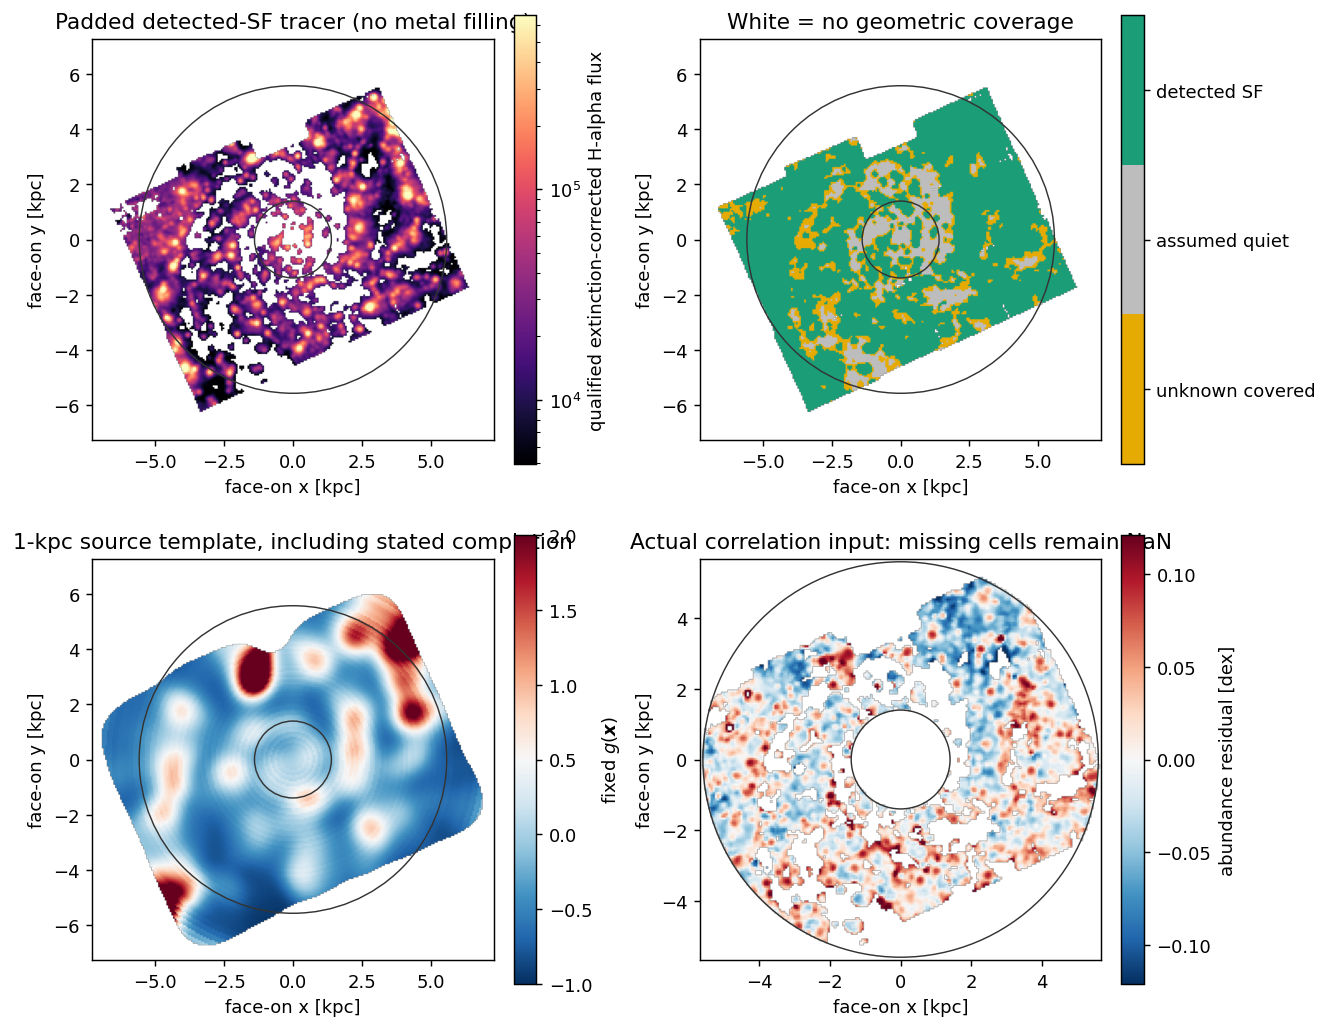

radius_kpc,full_area_kpc2,covered_area_kpc2,qualified_Halpha_flux,SF_cells,quiet_cells,unknown_cells,covered_area_surface_density,unknown_flux_sensitivity_scenario
float64,float64,float64,float64,float64,float64,float64,float64,float64
1.7460576549632525,7.662262384638493,7.5852,48264623.614167355,1017.0,652.0,438.0,6362999.474525043,750675.9782745457
2.444480716948554,10.72716733849389,10.760399999999999,122156064.62392618,2013.0,521.0,455.0,11352372.088763075,405802.3568333204
3.142903778933855,13.79207229234929,13.467599999999997,178487096.04753536,2878.0,249.0,614.0,13253073.750893656,373990.0606372326
3.841326840919156,16.856977246204668,15.2208,190369935.32625672,3509.0,138.0,581.0,12507222.703554131,248139.86937234542
4.5397499029044575,19.92188220006011,14.464799999999997,220097693.36663026,3244.0,380.0,394.0,15216089.635987384,170958.9769683415
5.23817296488976,22.986787153915486,11.2104,174257458.56805834,2592.0,138.0,384.0,15544267.695002707,198737.2109144095


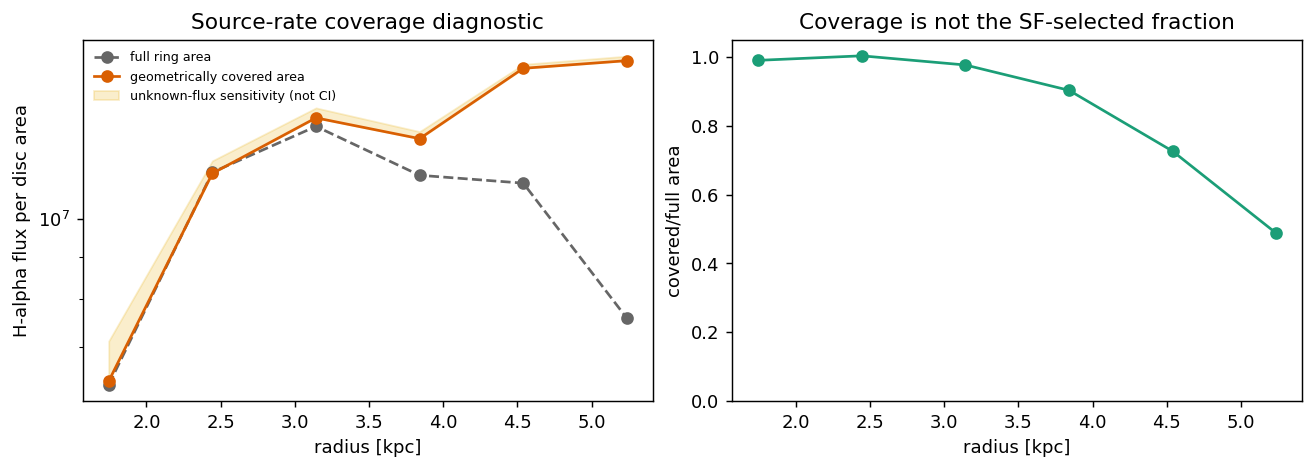

In [6]:
from matplotlib.colors import ListedColormap, LogNorm
with np.load(OUTPUT_DIR / "ngc628_padded_source_inputs.npz") as z:
    source_axis = z["source_axis_kpc"]
    source_extent = [source_axis[0]-.03, source_axis[-1]+.03]*2
    classes = np.full(z["geometric_coverage"].shape, np.nan)
    classes[z["unclassified_covered"]] = 0
    classes[z["assumed_quiet"]] = 1
    classes[z["detected_SF"]] = 2
    fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
    ha = z["selected_Halpha_flux"]
    positive = ha[np.isfinite(ha)&(ha > 0)]
    im = axes[0, 0].imshow(ha, origin="lower", extent=source_extent, cmap="magma",
        norm=LogNorm(*np.percentile(positive, [2, 99])))
    fig.colorbar(im, ax=axes[0, 0], label="qualified extinction-corrected H-alpha flux")
    axes[0, 0].set_title("Padded detected-SF tracer (no metal filling)")
    im = axes[0, 1].imshow(classes, origin="lower", extent=source_extent,
        cmap=ListedColormap(["#e6ab02", "#bdbdbd", "#1b9e77"]), vmin=-.5, vmax=2.5)
    cb = fig.colorbar(im, ax=axes[0, 1], ticks=[0, 1, 2])
    cb.ax.set_yticklabels(["unknown covered", "assumed quiet", "detected SF"])
    axes[0, 1].set_title("White = no geometric coverage")
    im = axes[1, 0].imshow(np.where(z["modulation_support"], z["source_modulation"], np.nan),
        origin="lower", extent=source_extent, cmap="RdBu_r", vmin=-1, vmax=2)
    fig.colorbar(im, ax=axes[1, 0], label=r"fixed $g(\boldsymbol{x})$")
    axes[1, 0].set_title("1-kpc source template, including stated completion")
    extent = [pixel_centres[0]-.03, pixel_centres[-1]+.03]*2
    lim = np.percentile(np.abs(pixel_residual_centered_grid[pixel_valid_grid]), 99)
    im = axes[1, 1].imshow(np.where(pixel_valid_grid, pixel_residual_centered_grid, np.nan),
        origin="lower", extent=extent, cmap="RdBu_r", vmin=-lim, vmax=lim)
    fig.colorbar(im, ax=axes[1, 1], label="abundance residual [dex]")
    axes[1, 1].set_title("Actual correlation input: missing cells remain NaN")
    for ax in axes.ravel():
        for radius in [R_MIN_KPC, R_MAX_KPC]:
            ax.add_patch(plt.Circle((0, 0), radius, fill=False, ec="0.2", lw=.8))
        ax.set(xlabel="face-on x [kpc]", ylabel="face-on y [kpc]")
    fig.savefig(OUTPUT_DIR / "ngc628_source_coverage_and_control_map.png", bbox_inches="tight")
    display_figure(fig)
profile = np.genfromtxt(OUTPUT_DIR / "ngc628_source_rate_coverage.csv", delimiter=",", names=True)
display(Table(profile))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
r = profile["radius_kpc"]
axes[0].plot(r, profile["qualified_Halpha_flux"]/profile["full_area_kpc2"], "o--", color="0.4", label="full ring area")
axes[0].plot(r, profile["covered_area_surface_density"], "o-", color="#d95f02", label="geometrically covered area")
axes[0].fill_between(r, profile["covered_area_surface_density"],
    profile["covered_area_surface_density"]+profile["unknown_flux_sensitivity_scenario"],
    color="#e6ab02", alpha=.2, label="unknown-flux sensitivity (not CI)")
axes[0].set(xlabel="radius [kpc]", ylabel="H-alpha flux per disc area", yscale="log", title="Source-rate coverage diagnostic")
axes[0].legend(frameon=False, fontsize=7)
axes[1].plot(r, profile["covered_area_kpc2"]/profile["full_area_kpc2"], "o-", color="#1b9e77")
axes[1].set(xlabel="radius [kpc]", ylabel="covered/full area", ylim=(0, 1.05), title="Coverage is not the SF-selected fraction")
fig.savefig(OUTPUT_DIR / "ngc628_source_rate_coverage.png", bbox_inches="tight")
display_figure(fig)


## 5. Physical response and independent numerical checks

Let $G_u$ be the sampled Gaussian operator from all padded injection sites to
all valid observed positions, with endpoint covariance
$V_u=\ell_*^2u I+B_{\rm sky\to faceon}$ and $u\in[\epsilon^2,1]$.
Here $B=\sigma_{\rm sky}^2 A^{\mathsf T}A$ for the measured affine transform;
**the full beam covariance is added**, not half of it. Uniform physical ages
give $w(u)du=du/(1-\epsilon^2)$, evaluated by log-$u$ Gauss quadrature.
Define $T=\int w(u)G_u\,du$, $\lambda=\lambda_0(1+\eta g)$ and
$\lambda_0=\exp[-(R-R_{\rm ref})/h_R]$. In dimensionless covariance units,

$$ C_{\rm 2p}=\frac{4\pi\kappa t_*}{\Delta A}
       \int w(u)G_u D_\lambda G_u^{\mathsf T}\,du,\quad
   C_{\rm M}=\beta(T\lambda)(T\lambda)^{\mathsf T},\quad
   C_{\rm NP}=(\beta A_{\rm src})
       T D_{\lambda_0} E_{\ell_{\rm src}}D_{\lambda_0}T^{\mathsf T}. $$

$\Delta A$ is source-pixel area, $D$ denotes a diagonal source-rate matrix,
and $E$ has Gaussian isotropic source-pair spectrum. The latter is represented
spectrally so correlation lengths below source-grid size do not create a
spurious finite point variance. After the source integrals, apply the actual
annular projector $P$ to all terms. Sum the raw pair numerators and arithmetic
endpoint second moments before taking their ratio. No covariance at $r>5$
kpc is dropped from the annular averages. The observed $r=0$ anchor is fixed
to one and excluded from fitting.

Tests compare with dense $PCP^{\mathsf T}$, the uniform KT18/CNP limits,
transported mean harmonics and finite-$q$ same-event attenuation. A separate
small-map check compares 16/32 age nodes, 60/30-pc source grids and padding.
These verify the numerical response at test points, not across the full prior.


In [7]:
from scripts.test_phangs_source_integral import run_tests
numerical_validation = run_tests()
(OUTPUT_DIR / "ngc628_source_integral_validation.json").write_text(json.dumps(numerical_validation, indent=2)+"\n")
display(numerical_validation)


{
  "dense": {
    "dense_CP_0": 1.7080781233858033e-13,
    "dense_CP_1": 1.7697648901915386e-14,
    "dense_mean_0": 1.742177365912645e-17,
    "dense_mean_1": 5.488773498207866e-17,
    "dense_mean_2": 1.214306433183765e-17,
    "dense_CNP": 6.106226635438361e-16
  },
  "analytic": {
    "uniform_overlap_max_error": 7.494005416219807e-16,
    "harmonic_overlap_max_error": 4.996003610813204e-16,
    "mean_transport_max_error": 7.494005416219807e-16,
    "CNP_uniform_analytic_max_error": 1.4502288259166107e-15,
    "omitted_harmonic_attenuation_max_error": 0.28003947349745223,
    "harmonic_q": 1.9600000000000002
  },
  "quadrature_and_grid": {
    "age_16_vs_32_curve_max_error": 1.7152945730458669e-13,
    "source_60_vs_30_pc_curve_max_error": 9.672199129595604e-05,
    "padding_1p56_vs_1p74_curve_max_error": 3.3306690738754696e-16,
    "scope": "one NGC628-like point on a small map; not full-prior convergence"
  },
  "scope": "discrete global source-integral algebra and analytic con

{'dense': {'dense_CP_0': 1.7080781233858033e-13,
  'dense_CP_1': 1.7697648901915386e-14,
  'dense_mean_0': 1.742177365912645e-17,
  'dense_mean_1': 5.488773498207866e-17,
  'dense_mean_2': 1.214306433183765e-17,
  'dense_CNP': 6.106226635438361e-16},
 'analytic': {'uniform_overlap_max_error': 7.494005416219807e-16,
  'harmonic_overlap_max_error': 4.996003610813204e-16,
  'mean_transport_max_error': 7.494005416219807e-16,
  'CNP_uniform_analytic_max_error': 1.4502288259166107e-15,
  'omitted_harmonic_attenuation_max_error': 0.28003947349745223,
  'harmonic_q': 1.9600000000000002},
 'quadrature_and_grid': {'age_16_vs_32_curve_max_error': 1.7152945730458669e-13,
  'source_60_vs_30_pc_curve_max_error': 9.672199129595604e-05,
  'padding_1p56_vs_1p74_curve_max_error': 3.3306690738754696e-16,
  'scope': 'one NGC628-like point on a small map; not full-prior convergence'},
 'scope': 'discrete global source-integral algebra and analytic continuum limits; not native-flux recovery or MCMC calibrat

## 6. Finite-map normalisation recovery — limited scope

On a fixed irregular small map, draw Gaussian fields with known connected
covariance plus the transported deterministic mean. Every valid pixel pair is
used in every realisation. Compare $E[N/D]$ with $E[N]/E[D]$ and report Monte
Carlo error. The shaded interval here is the **single-map estimator** spread,
not a posterior interval. This experiment does not supply an empirical bias
correction for NGC628, and is not native multi-line/selection recovery or SBC.


{'status': 'completed covariance-level small-map experiment',
 'realisations': 4000,
 'observed_pixels': 46,
 'ordered_pair_counts': [388, 566, 636, 390, 90],
 'mean_random_ratio': [0.621288415020741,
  0.09895407148577046,
  -0.2435722994059483,
  -0.301359949476743,
  -0.26331583064301567],
 'ratio_of_expected_moments': [0.6713540524878107,
  0.15762177548614392,
  -0.2610808261203776,
  -0.36231182907276305,
  -0.3426964104356566],
 'empirical_ratio_of_averaged_moments': [0.6688329489782429,
  0.15274451674997253,
  -0.2619816121892194,
  -0.3557305958091524,
  -0.3287110713464832],
 'Monte_Carlo_standard_error_of_mean_ratio': [0.0019070884201810349,
  0.0024842222500276677,
  0.001297408607693889,
  0.003034219650910537,
  0.006199757425057524],
 'normalisation_bias_mean_ratio_minus_ratio_of_moments': [-0.05006563746706971,
  -0.058667704000373466,
  0.01750852671442929,
  0.06095187959602005,
  0.0793805797926409],
 'scope': 'Gaussian covariance-level recovery on a fixed irregular

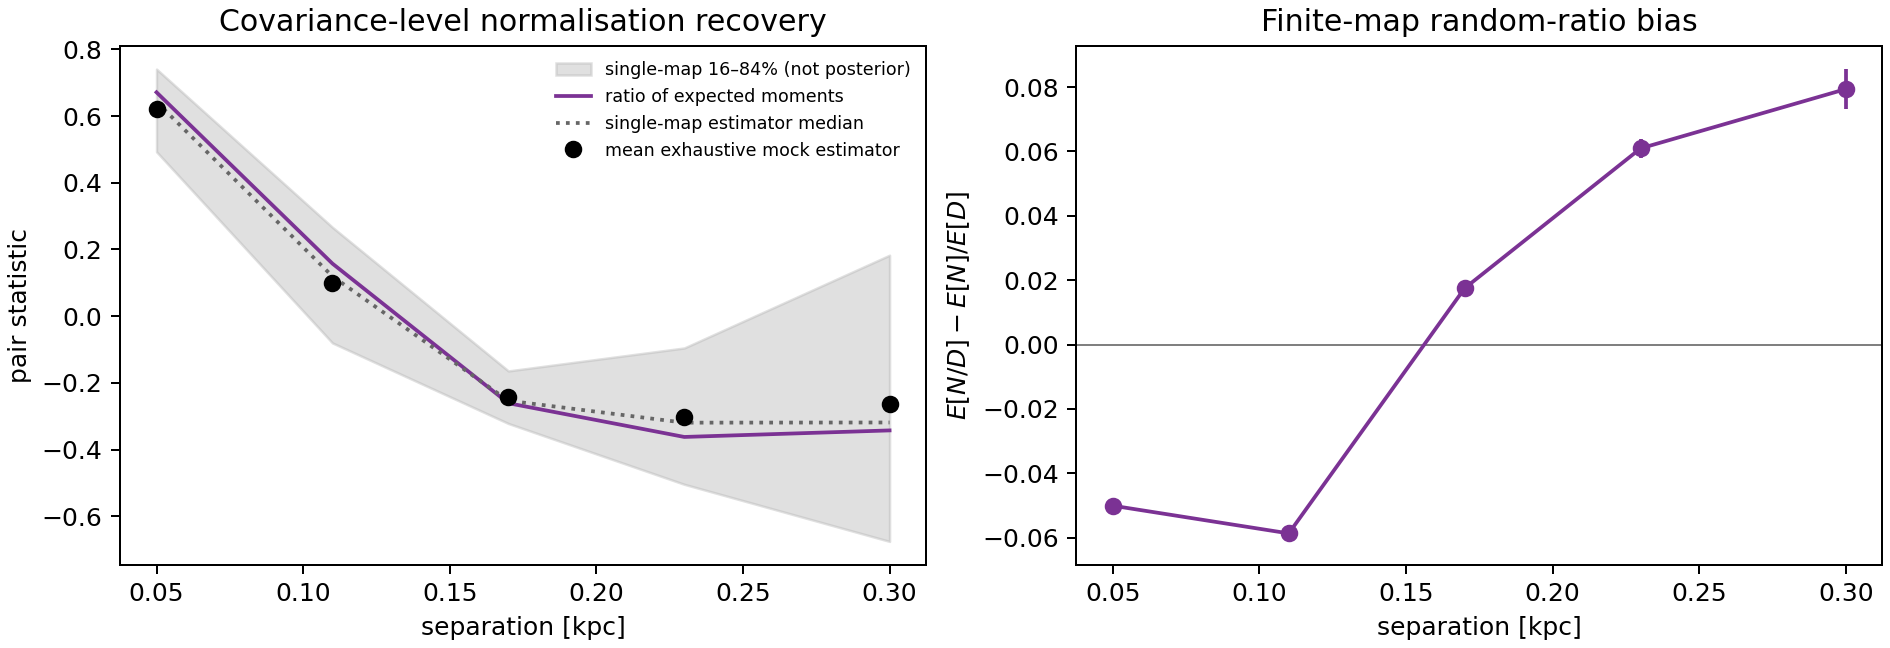

In [8]:
from scripts.phangs_source_ratio_recovery import run_ratio_recovery
normalisation_recovery = run_ratio_recovery(OUTPUT_DIR)
display(normalisation_recovery)
display(Image(filename=str(OUTPUT_DIR / "ngc628_small_map_ratio_recovery.png")))


## 7. Full real-data reference calculation (may take a long time)

The coordinate vector is one actual prior-run joint draw nearest its internal
coordinate medians. Hold it fixed while replacing the source/beam/integration
implementation. This is not resampling the posterior. The same old covariance
and measured noise response are frozen controls, not newly validated errors.
The component panel uses the latent signal and noise-adjusted data, so its four
stacked terms sum exactly to the displayed latent total without displaying a
measurement-noise component. The comparison panel includes the measured noise
response. No posterior band is drawn for this fixed point.

Progress: `ngc628_source_integral_progress.json` and the runner log in the
isolated output folder. Completed notebook cells are saved immediately. The
real-data reference result must not be reported as a successful new fit.


{'stage': 'same-event source integral', 'completed_age_nodes': 1, 'total_age_nodes': 32, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'same-event source integral', 'completed_age_nodes': 2, 'total_age_nodes': 32, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'same-event source integral', 'completed_age_nodes': 3, 'total_age_nodes': 32, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'same-event source integral', 'completed_age_nodes': 4, 'total_age_nodes': 32, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'same-event source integral', 'completed_age_nodes': 5, 'total_age_nodes': 32, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'same-event source integral', 'completed_age_nodes': 6, 'total_age_nodes': 32, 'ell_star_kpc': 0.15301688178063913}


... (44 outputs left out)

{'stage': 'nonlocal distinct-event integral', 'completed_pixels': 14408, 'total_pixels': 15201, 'source_length_kpc': 0.9078506325117714}


{'stage': 'nonlocal distinct-event integral', 'completed_pixels': 15201, 'total_pixels': 15201, 'source_length_kpc': 0.9078506325117714}


{'stage': 'source-integral point completed', 'elapsed_seconds': 129.8305401802063}


{'status': 'completed fixed-coordinate real-data reference calculation; NOT refitted',
 'fingerprint': 'd68292942b6931700b5e83b90e0ddaefb4db6b7565090674c84049d432526d34',
 'elapsed_seconds': 137.62730407714844,
 'coordinates': {'log_ell': -1.8772070252409891,
  'logit_epsilon': -1.9660595508376173,
  'log_beta': -0.08275545241728027,
  'log_arm_scale': -0.004696735459212648,
  'eta': 0.07049416828810354,
  'log_betaA': -1.8637967902362114,
  'log_source_length': -0.09667541555174064},
 'physical_shape_parameters': {'ell_star_kpc': 0.15301688178063913,
  'epsilon': 0.12281276002230032,
  'beta': 0.9205762443907934,
  'arm_scale': 0.9953142769552293,
  'eta_kpc_inv': 0.07049416828810354,
  'source_excess_amplitude': 0.16846262939069304,
  'source_length_kpc': 0.9078506325117714},
 'reference_coordinate_selection': 'one actual prior-run joint draw nearest the coordinatewise median, not a new pointwise posterior median',
 'ordered_pixel_pairs_in_positive_bins': 115366246,
 'valid_pixels': 

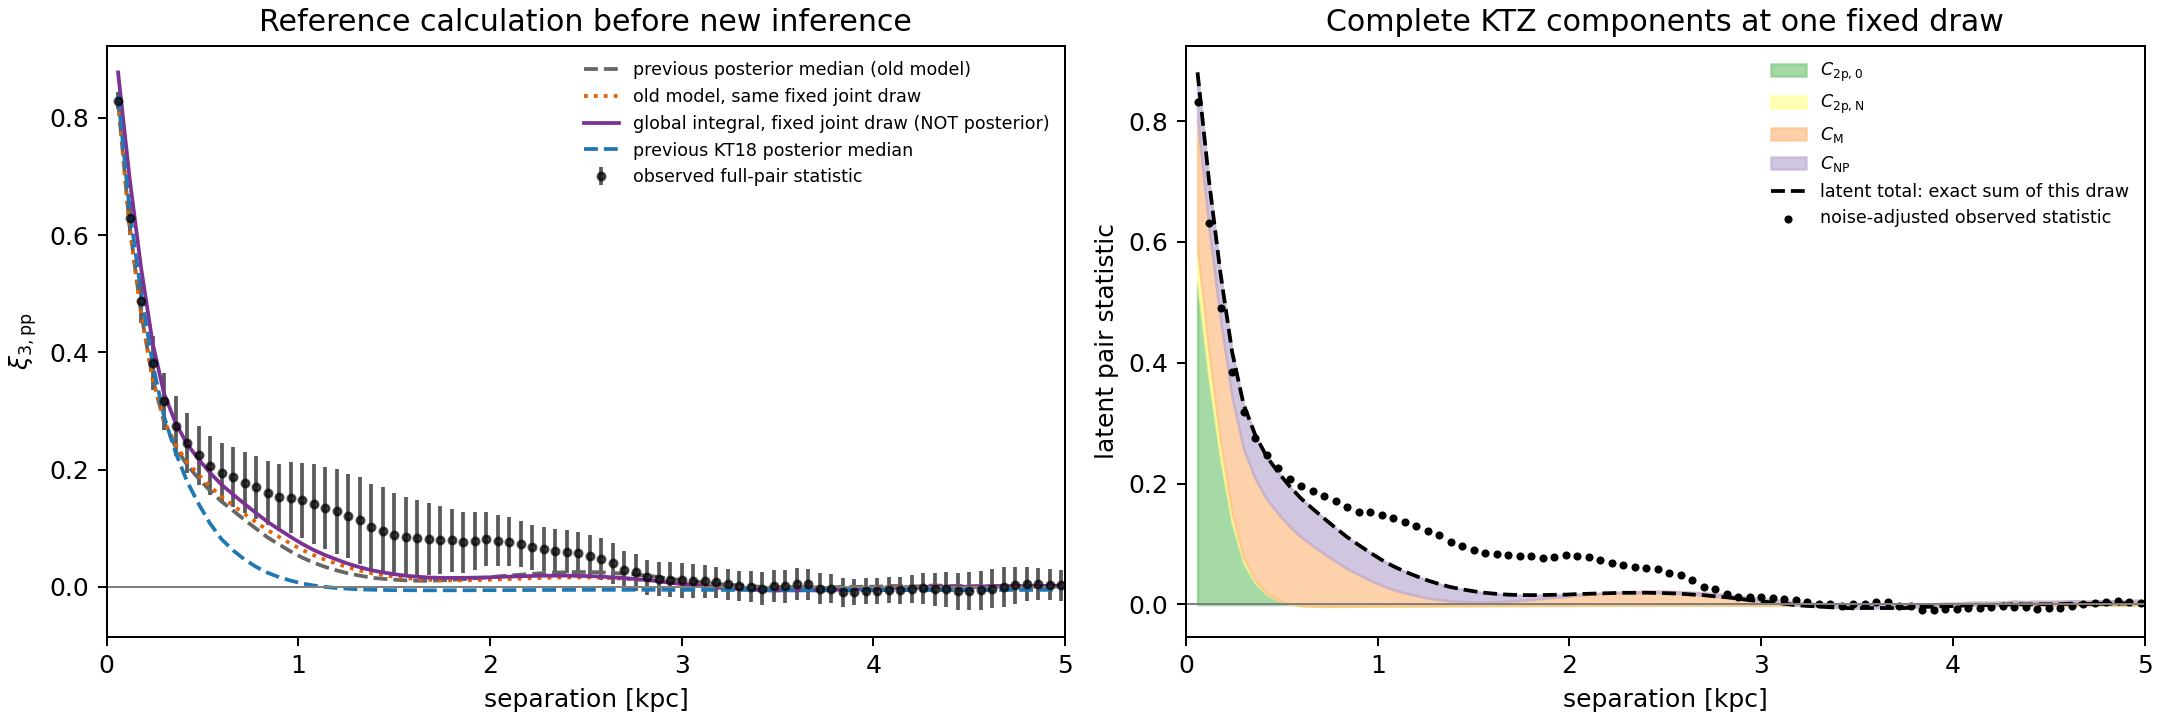

**Next gate:** full-prior numerical convergence and emulator checks; native-flux recovery; independent MCMC restarts. No new posterior has been substituted for the existing fits.

In [9]:
from scripts.reference_ngc628_source_integral import run_reference_point
reference_point_summary = run_reference_point(ROOT, OUTPUT_DIR)
display(reference_point_summary)
display(Image(filename=str(OUTPUT_DIR / "ngc628_global_source_reference_point.png")))
display(Markdown("**Next gate:** full-prior numerical convergence and emulator checks; native-flux recovery; independent MCMC restarts. No new posterior has been substituted for the existing fits."))


## 8. Independent-ensemble inference utility — analytic test only

Four separately seeded/initialised ensemble runs are compared. Rhat uses the
same selected walker trajectory across those **independent restarts**, never
treating interacting walkers from one run as independent chains. Target
functions include squared radius in the closed-form Gaussian test; time-series
MCSE/ESS are computed from independent ensemble-average functions. An
artificially shifted restart must be rejected. This is a sampler test, not
NGC628 posterior convergence or full simulation-based calibration.

These appended diagnostic cells can run in a separate kernel while preserving
the executed source/reference cells above.


In [1]:
import json
from pathlib import Path
from IPython.display import display
from scripts.phangs_independent_inference import test_gaussian_inference
independent_sampler_validation = test_gaussian_inference()
diagnostic_output = Path.cwd() / "outputs/implications/NGC628_source_integral_refit"
(diagnostic_output / "ngc628_independent_sampler_validation.json").write_text(json.dumps(independent_sampler_validation, indent=2)+"\n")
display(independent_sampler_validation)


{'independent_ensembles': 4,
 'retained_steps_per_ensemble': 18000,
 'walkers_per_ensemble': 16,
 'Rhat_walker_indices': [0, 4, 8, 12],
 'target_names': ['x0', 'x1', 'squared_radius'],
 'max_rank_folded_split_Rhat_across_selected_trajectories': [1.0023888589137713,
  1.0062256210546192,
  1.0011692792371303],
 'ensemble_mean_autocorrelation_times': [[31.30193320133711,
   36.35853874008,
   11.085602477050974],
  [32.952209288381255, 30.098300836947352, 9.298607320830595],
  [33.60774887084468, 36.98742750856054, 10.302664379098784],
  [29.782435871727397, 40.97072875724305, 11.76577974083368]],
 'target_function_MCSE': [0.0053204182585906016,
  0.005609103260991288,
  0.00602109018761834],
 'target_function_ESS': [35252.564144602264,
  31760.77309730334,
  109111.32159547321],
 'time_series_length_at_least_50_tau': True,
 'numerical_sampling_gate_passed': True,
 'scope': 'Closed-form Gaussian sampler test, NOT a new galaxy fit or SBC.',
 'gaussian_target_means': [-0.004866027805504974

## 9. Real-map quadrature/source-grid refinement (long calculation)

Retain all 15,201 observed pixels and the identical joint reference coordinate.
Compare 32 versus 64 age nodes at 60-pc source spacing, then 60 versus 30-pc
source integration grids at 32 nodes. The latter refines the **same saved
source template** bilinearly; it adds no observations. The observer grid,
source completion, beam, noise response and annular projector stay fixed.
Thresholds concern absolute correlation changes, not percentages.

Passing these checks validates this point only, not the full physical prior or
the unknown-source completion. The full prior, source boundary/quiet assumptions
and native-flux propagation still require separate tests before new MCMC.
Progress is in `ngc628_source_precision_progress.json`; each completed variant
is cached separately, so long runs resume without repeating completed variants.


{'stage': 'same-event source integral', 'completed_age_nodes': 1, 'total_age_nodes': 64, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'same-event source integral', 'completed_age_nodes': 2, 'total_age_nodes': 64, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'same-event source integral', 'completed_age_nodes': 3, 'total_age_nodes': 64, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'same-event source integral', 'completed_age_nodes': 4, 'total_age_nodes': 64, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'same-event source integral', 'completed_age_nodes': 5, 'total_age_nodes': 64, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'same-event source integral', 'completed_age_nodes': 6, 'total_age_nodes': 64, 'ell_star_kpc': 0.15301688178063913}


... (129 outputs left out)

{'stage': 'nonlocal distinct-event integral', 'completed_pixels': 14408, 'total_pixels': 15201, 'source_length_kpc': 0.9078506325117714}


{'stage': 'nonlocal distinct-event integral', 'completed_pixels': 15201, 'total_pixels': 15201, 'source_length_kpc': 0.9078506325117714}


{'stage': 'source-integral point completed', 'elapsed_seconds': 482.33459186553955}


{'status': 'completed fixed-coordinate real-map numerical refinement',
 'age_32_vs_64': {'max_absolute_curve_change': 4.272313613995493e-10,
  'elapsed_seconds': 131.5801260471344},
 'source_grid_60_vs_30_pc': {'max_absolute_curve_change': 0.000145113529263996,
  'elapsed_seconds': 482.3692102432251},
 'point_precision_gate_passed': True,
 'thresholds_absolute_xi': {'age': 0.0005, 'source_grid': 0.002},
 'all_observed_pixels': 15201,
 'ordered_pixel_pairs_in_positive_bins': 115366246,
 'scope': 'One fixed joint point, unchanged source completion and frozen measurement response. Not a new fit or full-prior precision gate.',
 'remaining': 'Prior-wide beam/grid/age/Gaussian-cutoff/boundary/source-completion tests, validated fast emulator, native-flux recovery, independent MCMC.'}

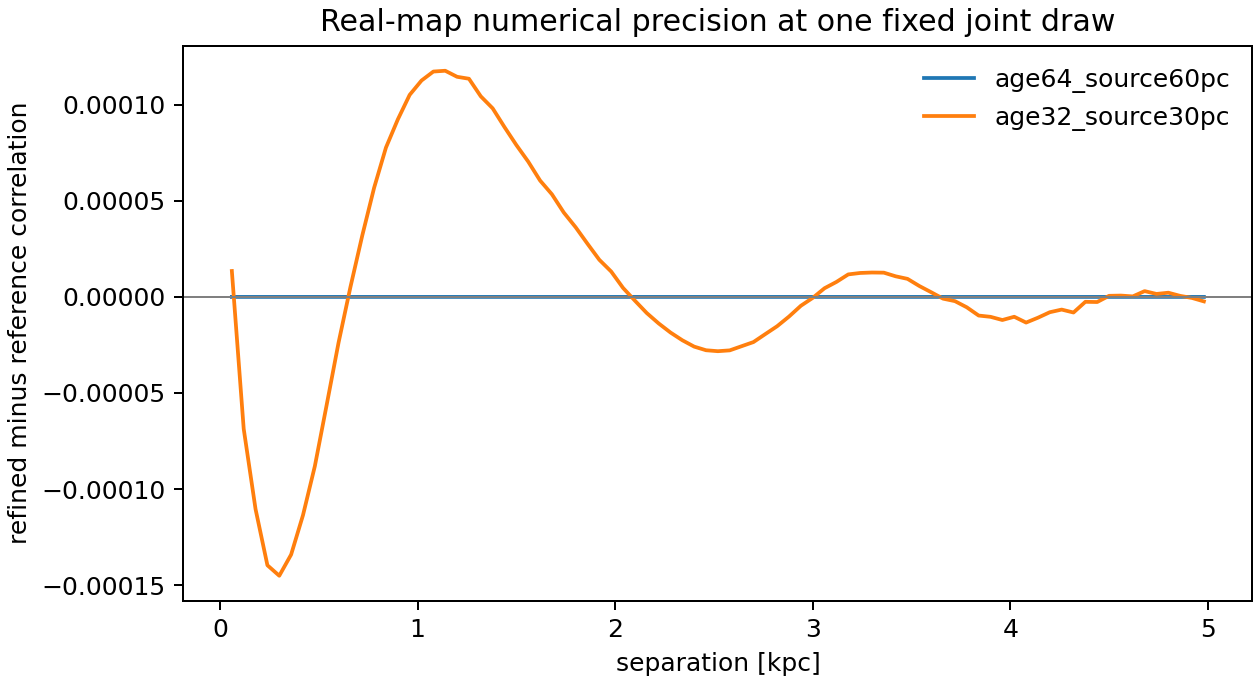

In [2]:
from pathlib import Path
from IPython.display import Image, display
from scripts.audit_ngc628_source_integral import run_precision_audit
diagnostic_output = Path.cwd() / "outputs/implications/NGC628_source_integral_refit"
real_map_precision_audit = run_precision_audit(Path.cwd(), diagnostic_output)
display(real_map_precision_audit)
display(Image(filename=str(diagnostic_output / "ngc628_source_precision_audit.png")))


## 10. Equivalent convolution integrator and real-map benchmark

For each age, multiplication by $G_u$ is a discrete Gaussian convolution, so
the source-matrix contractions can be evaluated without constructing a large
pixel-by-source sparse matrix. The distinct-event response is still exactly
$T D_{\lambda_0} E D_{\lambda_0}T^{\mathsf T}$ for the represented source grid:
for endpoint $j$, form $w_j=T_j\lambda_0$, convolve it with $E$, multiply by
$\lambda_0$, and convolve with $T$ before sampling **every** observed endpoint.
Row blocking limits memory; it does not subsample pixels or pairs.

The real-map benchmark must reproduce the original raw four-term moments and
the complete fixed-coordinate KTZ curve before a reusable response table is
built. Gaussian truncation, grid, source completion and physical amplitudes
remain unchanged. This is numerical equivalence, not a new fit.


In [1]:
import json
from pathlib import Path
from IPython.display import display
from scripts.test_phangs_source_fft import run_fft_tests
from scripts.test_phangs_age_response import run_age_response_tests
from scripts.build_ngc628_age_library import run_fft_benchmark
diagnostic_output = Path.cwd() / "outputs/implications/NGC628_source_integral_refit"
convolution_checks = run_fft_tests()
single_age_checks = run_age_response_tests()
(diagnostic_output / "ngc628_fft_algebra_validation.json").write_text(json.dumps(
    {"convolution": convolution_checks, "single_age": single_age_checks}, indent=2)+"\n")
display(single_age_checks)
fft_real_map_benchmark = run_fft_benchmark(Path.cwd(), diagnostic_output)
display(fft_real_map_benchmark)


{
  "status": "convolution algebra verified against original discrete source operators",
  "checks": [
    {
      "CP": 5.551115123125783e-17,
      "mean": 3.469446951953614e-17,
      "CNP": 1.942890293094024e-16,
      "eta": 0.25,
      "source_length_kpc": 0.08,
      "curve_error": 2.7755575615628914e-16
    },
    {
      "CP": 8.326672684688674e-17,
      "mean": 2.7755575615628914e-17,
      "CNP": 1.3010426069826053e-18,
      "eta": -0.3,
      "source_length_kpc": 0.005,
      "curve_error": 2.220446049250313e-16
    },
    {
      "CP": 8.326672684688674e-17,
      "mean": 2.2551405187698492e-17,
      "CNP": 4.0158848468863084e-16,
      "eta": 0.35,
      "source_length_kpc": 0.8,
      "curve_error": 5.551115123125783e-16
    }
  ],
  "scope": "Independent irregular small-map exact discrete checks; not full-prior emulator validation."
}


{'status': 'single-age full-pair responses match direct source matrices',
 'max_absolute_density_response_errors': [1.3393730569077889e-12,
  3.1730174043786974e-13,
  1.4317436125566019e-12,
  3.3872904481313526e-13,
  1.5081269566508126e-12,
  3.566036355096003e-13],
 'scope': 'single-age algebra only; no CNP emulator or galaxy fit supplied by this library'}

{'stage': 'FFT same-event source integral', 'completed_age_nodes': 1, 'total_age_nodes': 32, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'FFT same-event source integral', 'completed_age_nodes': 2, 'total_age_nodes': 32, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'FFT same-event source integral', 'completed_age_nodes': 3, 'total_age_nodes': 32, 'ell_star_kpc': 0.15301688178063913}


{'stage': 'FFT same-event source integral', 'completed_age_nodes': 4, 'total_age_nodes': 32, 'ell_star_kpc': 0.15301688178063913}


... (46 outputs left out)

{'stage': 'FFT nonlocal distinct-event integral', 'completed_pixels': 14404, 'total_pixels': 15201, 'source_length_kpc': 0.9078506325117714}


{'stage': 'FFT nonlocal distinct-event integral', 'completed_pixels': 15201, 'total_pixels': 15201, 'source_length_kpc': 0.9078506325117714}


{'stage': 'FFT source-integral point completed', 'elapsed_seconds': 55.54157090187073}


{'status': 'real-map convolution equivalence passed',
 'fingerprint': 'da5b31af0c75eaeedc5fb81ffb7afb4ae253b8acb95b4f6e727b1c35a40fec13',
 'raw_moment_max_absolute_errors': {'CP': 4.440892098500626e-16,
  'mean': 4.996003610813204e-16,
  'CNP': 4.9960036108132044e-15},
 'complete_KTZ_curve_max_error': 6.661338147750939e-16,
 'new_end_to_end_seconds': 63.12934613227844,
 'new_integral_seconds': 55.54157090187073,
 'previous_reference_end_to_end_seconds': 137.62730407714844,
 'valid_pixels': 15201,
 'ordered_pairs_in_positive_bins': 115366246,
 'scope': 'Same fixed seven-coordinate point and source/beam/window/noise model. Not a new fit or full-prior emulator.'}

## 11. Reusable physical-age responses for CP and transported mean

This table contains the same-event covariance density and transported mean
fields at 65 intrinsic-variance nodes and nine external radial-rate slopes.
The variance range $0.015^2\le v\le3.2^2$ kpc$^2$ covers the existing injection
floor and transport-grid bound; $-0.35\le h_R^{-1}\le0.35$ kpc$^{-1}$ is unchanged.
For broad kernels the source grid expands to cover the required Gaussian
support. Newly included cells use the **same stated** axisymmetric exponential
extrapolation with $g=0$ outside measured support; this adds no observations or
new free parameters. Uncertain outer-disc source completion remains a separate
systematic, particularly for broad transport kernels.

Full pair-midpoint weights are accumulated once per variance node, not sampled,
then reused for all slopes. If $a=\sigma^2$ and $b=\ell_*^2$, uniform physical
ages imply
$$ C_{\rm 2p}=2\pi\int_a^b C_{\rm age}(v)\,dv,\qquad
   P T\lambda=\frac{1}{b-a}\int_a^b P G_v\lambda\,dv. $$
The prefactor follows from $\kappa t_*=(b-a)/2$. Splines are integrated in
**physical variance**, not log variance, even though nodes are log-spaced.
The output retains unnormalised covariance moments and projected mean fields.
Pair normalisation is applied only after their physical amplitudes are combined.

The table is checked against the known age-integrated reference point and
additional direct single-age points that are not knots. **It does not supply
a variable nonlocal CNP emulator and is not a complete KTZ fitting likelihood.**
For the reference check only, CNP is held at its independently integrated exact
value. No Poisson-only KTZ is fitted. Independent posterior resampling still
awaits the complete validated response and observing-recovery checks.

Progress: `ngc628_age_library_progress.json`. Each completed width node is
fingerprinted and saved in `single_age_response_nodes/`; interrupted table
generation resumes from those nodes without repeating completed work.


{'stage': 'single-age CP/mean response library', 'completed_width_nodes': 1, 'total_width_nodes': 65, 'slopes_per_width': 9, 'intrinsic_sigma_kpc': 0.015, 'last_node_seconds': 2.890120029449463, 'not_a_new_posterior': True}


{'stage': 'single-age CP/mean response library', 'completed_width_nodes': 2, 'total_width_nodes': 65, 'slopes_per_width': 9, 'intrinsic_sigma_kpc': 0.016311083145785676, 'last_node_seconds': 2.8198869228363037, 'not_a_new_posterior': True}


{'stage': 'single-age CP/mean response library', 'completed_width_nodes': 3, 'total_width_nodes': 65, 'slopes_per_width': 9, 'intrinsic_sigma_kpc': 0.01773676222591557, 'last_node_seconds': 2.833264112472534, 'not_a_new_posterior': True}


{'stage': 'single-age CP/mean response library', 'completed_width_nodes': 4, 'total_width_nodes': 65, 'slopes_per_width': 9, 'intrinsic_sigma_kpc': 0.019287053560262637, 'last_node_seconds': 2.7845001220703125, 'not_a_new_posterior': True}


{'stage': 'single-age CP/mean response library', 'completed_width_nodes': 5, 'total_width_nodes': 65, 'slopes_per_width': 9, 'intrinsic_sigma_kpc': 0.020972848950577706, 'last_node_seconds': 2.815586805343628, 'not_a_new_posterior': True}


{'stage': 'single-age CP/mean response library', 'completed_width_nodes': 6, 'total_width_nodes': 65, 'slopes_per_width': 9, 'intrinsic_sigma_kpc': 0.02280599220245846, 'last_node_seconds': 2.815601110458374, 'not_a_new_posterior': True}


... (56 outputs left out)

{'stage': 'single-age CP/mean response library', 'completed_width_nodes': 63, 'total_width_nodes': 65, 'slopes_per_width': 9, 'intrinsic_sigma_kpc': 2.7062436417998628, 'last_node_seconds': 12.188577651977539, 'not_a_new_posterior': True}


{'stage': 'single-age CP/mean response library', 'completed_width_nodes': 64, 'total_width_nodes': 65, 'slopes_per_width': 9, 'intrinsic_sigma_kpc': 2.9427843369434266, 'last_node_seconds': 15.585690021514893, 'not_a_new_posterior': True}


{'stage': 'single-age CP/mean response library', 'completed_width_nodes': 65, 'total_width_nodes': 65, 'slopes_per_width': 9, 'intrinsic_sigma_kpc': 3.2, 'last_node_seconds': 16.55311393737793, 'not_a_new_posterior': True}


{'status': 'CP/mean response library completed; CNP emulation and MCMC not completed',
 'variance_nodes': 65,
 'slope_nodes': 9,
 'intrinsic_sigma_range_kpc': [0.015, 3.2],
 'eta_range_kpc_inv': [-0.35, 0.35],
 'training_node_seconds_sum': 295.52668809890747,
 'reference_age_integrated_curve_error_CNP_held_exact': 3.6960441410771594e-06,
 'withheld_single_age_points': [{'intrinsic_variance_kpc2': 0.0007,
   'eta_kpc_inv': -0.299,
   'single_age_probe_curve_max_error': 6.432027882803497e-07},
  {'intrinsic_variance_kpc2': 0.012,
   'eta_kpc_inv': 0.103,
   'single_age_probe_curve_max_error': 8.520715702009518e-06},
  {'intrinsic_variance_kpc2': 0.22,
   'eta_kpc_inv': 0.319,
   'single_age_probe_curve_max_error': 1.2459434800549118e-06},
  {'intrinsic_variance_kpc2': 3.0,
   'eta_kpc_inv': 0.103,
   'single_age_probe_curve_max_error': 3.6865399099306195e-05}],
 'tested_CP_mean_precision_gate_passed': True,
 'all_pixel_pairs_retained': True,
 'valid_pixels': 15201,
 'interpretation': 'CN

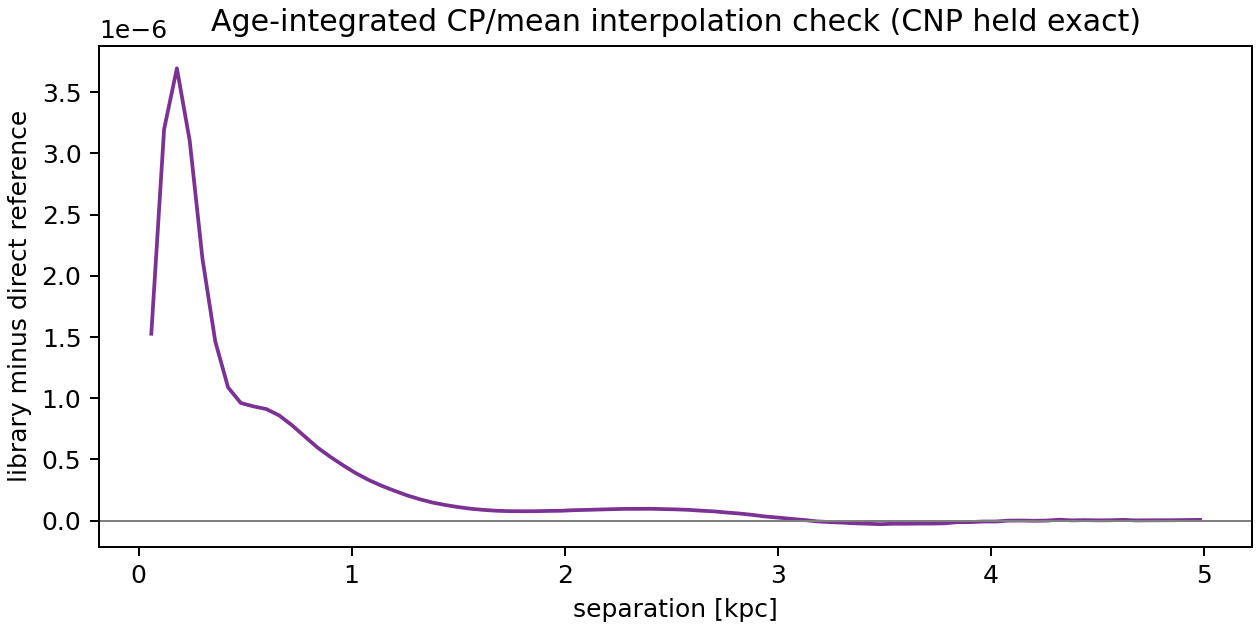

In [2]:
from pathlib import Path
from IPython.display import Image, display
from scripts.build_ngc628_age_library import build_age_library
diagnostic_output = Path.cwd() / "outputs/implications/NGC628_source_integral_refit"
age_response_library_validation = build_age_library(Path.cwd(), diagnostic_output)
display(age_response_library_validation)
display(Image(filename=str(diagnostic_output / "ngc628_age_library_validation.png")))


## 12. Analytic CNP regression control — not another physical component

For uniform source intensity, Gaussian source excess reduces exactly to a
triangular age-sum integral. With $z=s/t_*+s'/t_*$, its weight is $z$ on
$0<z<1$ and $2-z$ on $1<z<2$. The Gaussian endpoint covariance is
$$ [\ell_{\rm src}^2+2\sigma^2+2\kappa t_*z]I+2B. $$
The full elliptical beam is retained. Project the raw covariance moments on
the actual footprint before taking any ratio.

Multiplication by endpoint radial rates is **only a cheap regression control**,
not the physical variable-rate nonlocal CNP. The next step learns its
deterministic difference from $T D_{\lambda_0} E D_{\lambda_0}T^{\mathsf T}$ using
source integrals. Both pieces represent **one CNP**; neither is fitted
separately to galaxy data. No physical parameter is added to the seven coordinates.


In [1]:
import json
from pathlib import Path
from IPython.display import display
from scripts.phangs_cnp_baseline import test_gaussian_control
from scripts.build_ngc628_cnp_pilot import build_gaussian_control
diagnostic_output = Path.cwd() / "outputs/implications/NGC628_source_integral_refit"
cnp_gaussian_algebra = test_gaussian_control()
(diagnostic_output / "ngc628_cnp_control_algebra.json").write_text(json.dumps(cnp_gaussian_algebra, indent=2)+"\n")
display(cnp_gaussian_algebra)
cnp_control_summary = build_gaussian_control(Path.cwd(), diagnostic_output)
display(cnp_control_summary)


{'status': 'Gaussian endpoint control and exact age-sum integral verified',
 'dense_covariance_errors': [2.6645352591003757e-14,
  2.4868995751603507e-14,
  3.730349362740526e-14],
 'scope': 'This control is not the variable-rate nonlocal CNP theory; no galaxy fit uses it alone.'}

{'stage': 'Gaussian CNP regression control (not full theory)', 'completed_width_nodes': 1, 'total_width_nodes': 81}


{'stage': 'Gaussian CNP regression control (not full theory)', 'completed_width_nodes': 2, 'total_width_nodes': 81}


{'stage': 'Gaussian CNP regression control (not full theory)', 'completed_width_nodes': 3, 'total_width_nodes': 81}


{'stage': 'Gaussian CNP regression control (not full theory)', 'completed_width_nodes': 4, 'total_width_nodes': 81}


{'stage': 'Gaussian CNP regression control (not full theory)', 'completed_width_nodes': 5, 'total_width_nodes': 81}


... (73 outputs left out)

{'stage': 'Gaussian CNP regression control (not full theory)', 'completed_width_nodes': 79, 'total_width_nodes': 81}


{'stage': 'Gaussian CNP regression control (not full theory)', 'completed_width_nodes': 80, 'total_width_nodes': 81}


{'stage': 'Gaussian CNP regression control (not full theory)', 'completed_width_nodes': 81, 'total_width_nodes': 81}


{'status': 'Gaussian regression control completed; not the nonlocal CNP likelihood',
 'variance_nodes': 81,
 'slope_nodes': 9,
 'next': 'Train deterministic nonlocal source-integral differences and validate held-out points.'}

## 13. Nonlocal CNP source-response pilot and independent holdouts

Training covers the existing physical shape ranges in $\log(\kappa t_*)$,
$\log\sigma$, $h_R^{-1}$ and $\log\ell_{\rm src}$, with unchanged transport-grid
limits. Sixty-four space-filling points plus the stored exact reference point
train the numerical interpolation; 16 separately generated points are held out.
**Every observed pixel/pair** enters each source integral. These are theoretical
parameter-space samples, not a subset of the metallicity pixels.

For conditioning, the numerical residual is scaled by the uniform-source
zero-lag covariance. The observed metallicity correlation is never a training
target. Holdouts check positive second moments, the projected CNP-only shape and
complete-component mixtures over broad amplitude settings. The CNP-only shape
is a numerical diagnostic, not another fitted KTZ model.

Absolute correlation tolerance: 0.002. A failed pilot is **not ready for
inference**; no observational noise floor or narrower astrophysical prior is
introduced to pass it. Passing these points is not full-domain/source-completion
or native-line-selection validation. No posterior is automatically substituted.

Each exact point is checkpointed and code/input fingerprinted. Progress is in
`ngc628_cnp_pilot_progress.json`, with endpoint details in
`ngc628_cnp_pilot_integral_progress.json`. This stage may take hours.


{'stage': 'FFT nonlocal distinct-event integral', 'completed_pixels': 2, 'total_pixels': 15201, 'source_length_kpc': 0.5548371066418483}


{'stage': 'FFT nonlocal distinct-event integral', 'completed_pixels': 402, 'total_pixels': 15201, 'source_length_kpc': 0.5548371066418483}


{'stage': 'FFT nonlocal distinct-event integral', 'completed_pixels': 802, 'total_pixels': 15201, 'source_length_kpc': 0.5548371066418483}


{'stage': 'FFT nonlocal distinct-event integral', 'completed_pixels': 1202, 'total_pixels': 15201, 'source_length_kpc': 0.5548371066418483}


{'stage': 'FFT nonlocal distinct-event integral', 'completed_pixels': 1602, 'total_pixels': 15201, 'source_length_kpc': 0.5548371066418483}


{'stage': 'FFT nonlocal distinct-event integral', 'completed_pixels': 2002, 'total_pixels': 15201, 'source_length_kpc': 0.5548371066418483}


... (3,192 outputs left out)

{'stage': 'FFT nonlocal distinct-event integral', 'completed_pixels': 14802, 'total_pixels': 15201, 'source_length_kpc': 0.12666121977787503}


{'stage': 'FFT nonlocal distinct-event integral', 'completed_pixels': 15201, 'total_pixels': 15201, 'source_length_kpc': 0.12666121977787503}


{'stage': 'nonlocal CNP source-integral pilot', 'completed_points': 81, 'total_points': 81, 'role': 'heldout', 'ell_star_kpc': 0.5858150347380368, 'epsilon': 0.06647004260460151, 'eta_kpc_inv': -0.1605857933871448, 'source_length_kpc': 0.12666121977787503, 'elapsed_seconds': 11866.020514726639, 'not_a_galaxy_fit': True}


{'status': 'nonlocal CNP pilot completed; no new galaxy posterior sampled',
 'training_points': 65,
 'independent_heldout_points': 16,
 'tested_CNP_precision_gate_passed': False,
 'absolute_xi_tolerance': 0.002,
 'heldout_diagnostics': [{'heldout_index': 0,
   'positive_second_moments': True,
   'CNP_only_shape_error': 0.0010945239126904024,
   'maximum_mixture_probe_curve_error': 0.001094516671820072,
   'ell_star_kpc': 0.18439110025965796,
   'epsilon': 0.7257875386416538,
   'eta_kpc_inv': 0.08775043077766892},
  {'heldout_index': 1,
   'positive_second_moments': True,
   'CNP_only_shape_error': 0.0011817724580140184,
   'maximum_mixture_probe_curve_error': 0.0011797926142128445,
   'ell_star_kpc': 0.47662533242991667,
   'epsilon': 0.05251235703628866,
   'eta_kpc_inv': -0.19926082091405986},
  {'heldout_index': 2,
   'positive_second_moments': True,
   'CNP_only_shape_error': 0.008828011483745693,
   'maximum_mixture_probe_curve_error': 0.008827117430419404,
   'ell_star_kpc': 1.2

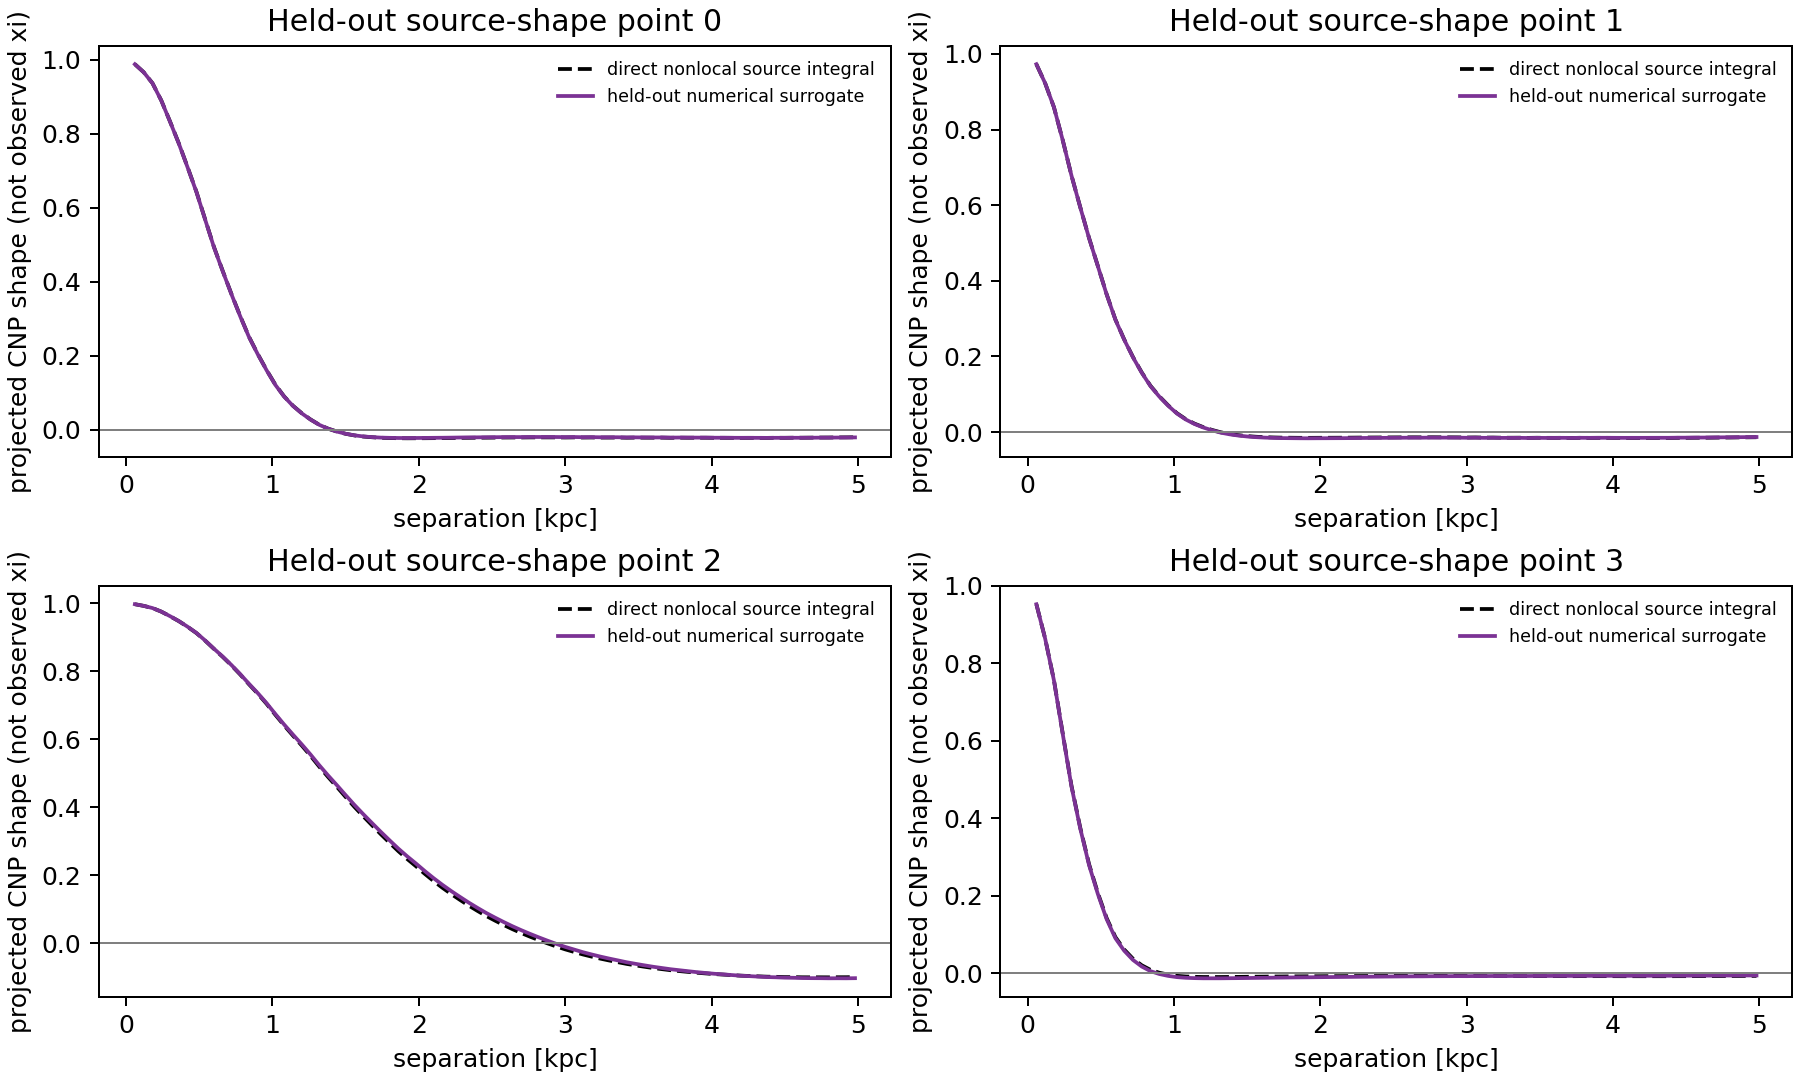

In [2]:
from pathlib import Path
from IPython.display import Image, display
from scripts.build_ngc628_cnp_pilot import run_cnp_pilot
diagnostic_output = Path.cwd() / "outputs/implications/NGC628_source_integral_refit"
cnp_pilot_validation = run_cnp_pilot(Path.cwd(), diagnostic_output)
display(cnp_pilot_validation)
display(Image(filename=str(diagnostic_output / "ngc628_cnp_pilot_holdouts.png")))


## 14. Failed CNP pilot and bounded refinement

The first 65-training/16-holdout pilot **failed** the predefined 0.002 absolute
correlation tolerance (largest pure-CNP shape error 0.0255). Its products remain
unchanged. All 81 exact source responses are now development data, including
the old holdouts: those 16 points are **not** independent validation any more.

The refined numerical representation models the correction to the normalised
CNP shape and the logarithm of its projected second moment, then reconstructs
one $(N,D)$ CNP response **before** combining KTZ components. This enforces a
positive second moment, not a positive correlation: signed projected tails
remain allowed. The control/correction are not separate physical terms and
add no fit parameter. Numerical settings use fixed five-fold source-response
cross-validation, never observed metallicity values. An optional radial-slope
factor imposes the homogeneous continuum control at zero slope; fresh zero-
slope tests explicitly check its discretisation error.

Each of at most two stages adds 128 maximin source-parameter training points
and freezes the numerical representation before evaluating 16 NEW random
holdouts and 8 NEW limit tests. If stage 1 fails, its tests may become stage-2
development data, but stage 2 uses new tests. Observing pixels/pairs are never
sampled. Physical priors, source completion, age quadrature and the CNP
definition remain unchanged.

Besides shape error, validation bounds the error for **any positive allocation**
to the other KTZ terms: with $h=D_{
m fast}/D_{
m true}$, it is bounded by
$|\xi_{
m fast}-\xi_{
m true}|+2\tanh(|\ln h|/4)$. Thus a good normalised
CNP curve cannot conceal an incorrect component amplitude. The 0.002 bound
is a numerical gate, not an extra observational noise floor. Native-flux
recovery and the remaining prior/source-boundary tests are still required;
this job does not start MCMC or replace manuscript results.

In [1]:
from pathlib import Path
import json
from IPython.display import Image, display
from scripts.refine_ngc628_cnp_response import development_audit, run_refinement_stage
refine_root = Path.cwd()
if not (refine_root/'scripts').is_dir():
    raise RuntimeError('Run from the manuscript workspace root.')
refine_output = refine_root/'outputs/implications/NGC628_source_integral_refit'
refine_folder = refine_output/'cnp_refinement_v1'
print(json.dumps(development_audit(refine_root, refine_output), indent=2))

{
  "status": "legacy teacher cross-validation; NOT new independent validation",
  "development_points": 81,
  "selected_numerical_settings": {
    "kind": "variance",
    "sigma_weight": 0.25,
    "kernel": "quintic",
    "eta_factor": true
  },
  "mixture_bound_algebra": {
    "status": "positive-allocation error bound verified",
    "random_allocations": 10000,
    "maximum_violation": -0.005548947918662134,
    "scope": "Numerical bound only; no observed fit or physical validation."
  },
  "inference_ready": false
}


In [ ]:
refine_stage_1 = run_refinement_stage(refine_root, refine_output, stage=0)
print(json.dumps({k:v for k,v in refine_stage_1.items() if k != 'diagnostics'}, indent=2))
for suffix in ('worst_shape_tests', 'mixture_error_tests'):
    image_path = refine_folder/f'stage_1_{suffix}.png'
    if image_path.exists():
        display(Image(filename=str(image_path)))

In [ ]:
refine_stage_2 = run_refinement_stage(refine_root, refine_output, stage=1)
print(json.dumps({k:v for k,v in refine_stage_2.items() if k != 'diagnostics'}, indent=2))
for suffix in ('worst_shape_tests', 'mixture_error_tests'):
    image_path = refine_folder/f'stage_2_{suffix}.png'
    if image_path.exists():
        display(Image(filename=str(image_path)))